# How Do Employers’ Filing Choices Relate to Department of Labor LCA Decisions?

This notebook analyzes the U.S. Department of Labor’s Office of Foreign Labor Certification (OFLC) FY2026 Q3 Labor Condition Application (LCA) disclosure data. It examines whether selected filing characteristics—
employer filing history, use of an agent, and wage choices—are **associated with** an application being withdrawn or denied.

The notebook prepares the data, explores patterns in an exploration sample, and evaluates planned comparisons in a separate confirmation sample. “Not certified” means **Withdrawn or Denied**. “Certified - Withdrawn” is counted as certified because the application was certified before it was withdrawn.

These results describe associations. They do not show that a filing choice caused a Department of Labor decision, and an LCA decision is not a visa decision.

**Source file:** `LCA_Disclosure_Data_FY2026_Q3.csv`  
**Raw data:** 437,496 applications and 98 columns  
**Prepared data:** 427,599 applications and 430 columns (9,423 repeated rows and 474 rows with implausible wages removed)  
**Source URL and download date:** See the report.

## Setup and Feature-Cleaning Functions

The next cell imports libraries and defines the input and output paths, columns to retain, wage-unit conversions, cleaning rules, derived features, and helper functions. It also contains the main analysis function. Check the configured input path before running the notebook in a new environment.

shape: (437496, 98)

Overall class distribution:
                            n       %
CASE_STATUS                          
Certified              401412  91.752
Certified - Withdrawn   26303   6.012
Withdrawn                7224   1.651
Denied                   2557   0.584

[before] 13 numeric cols, 30 categorical cols


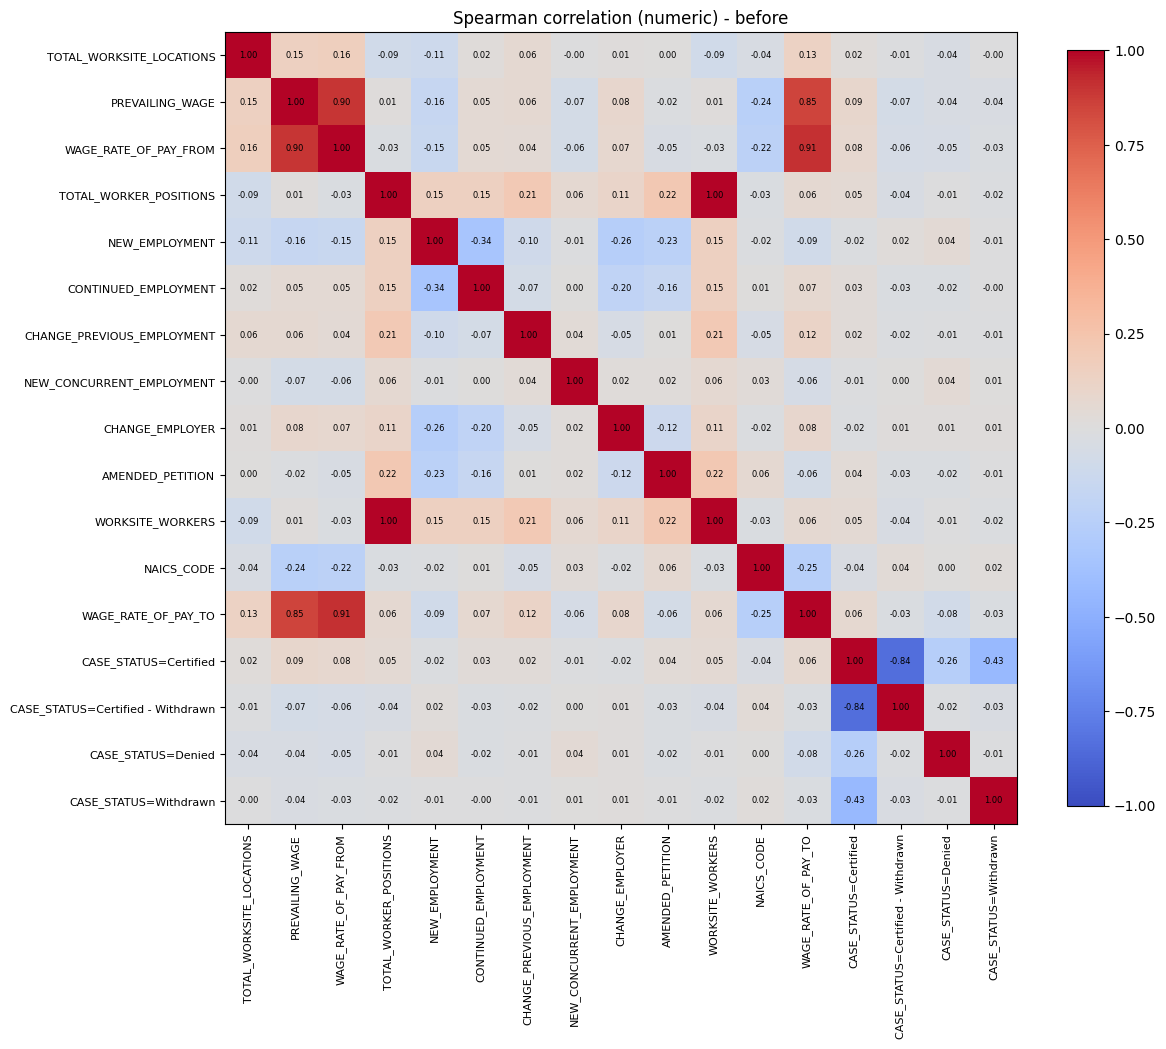

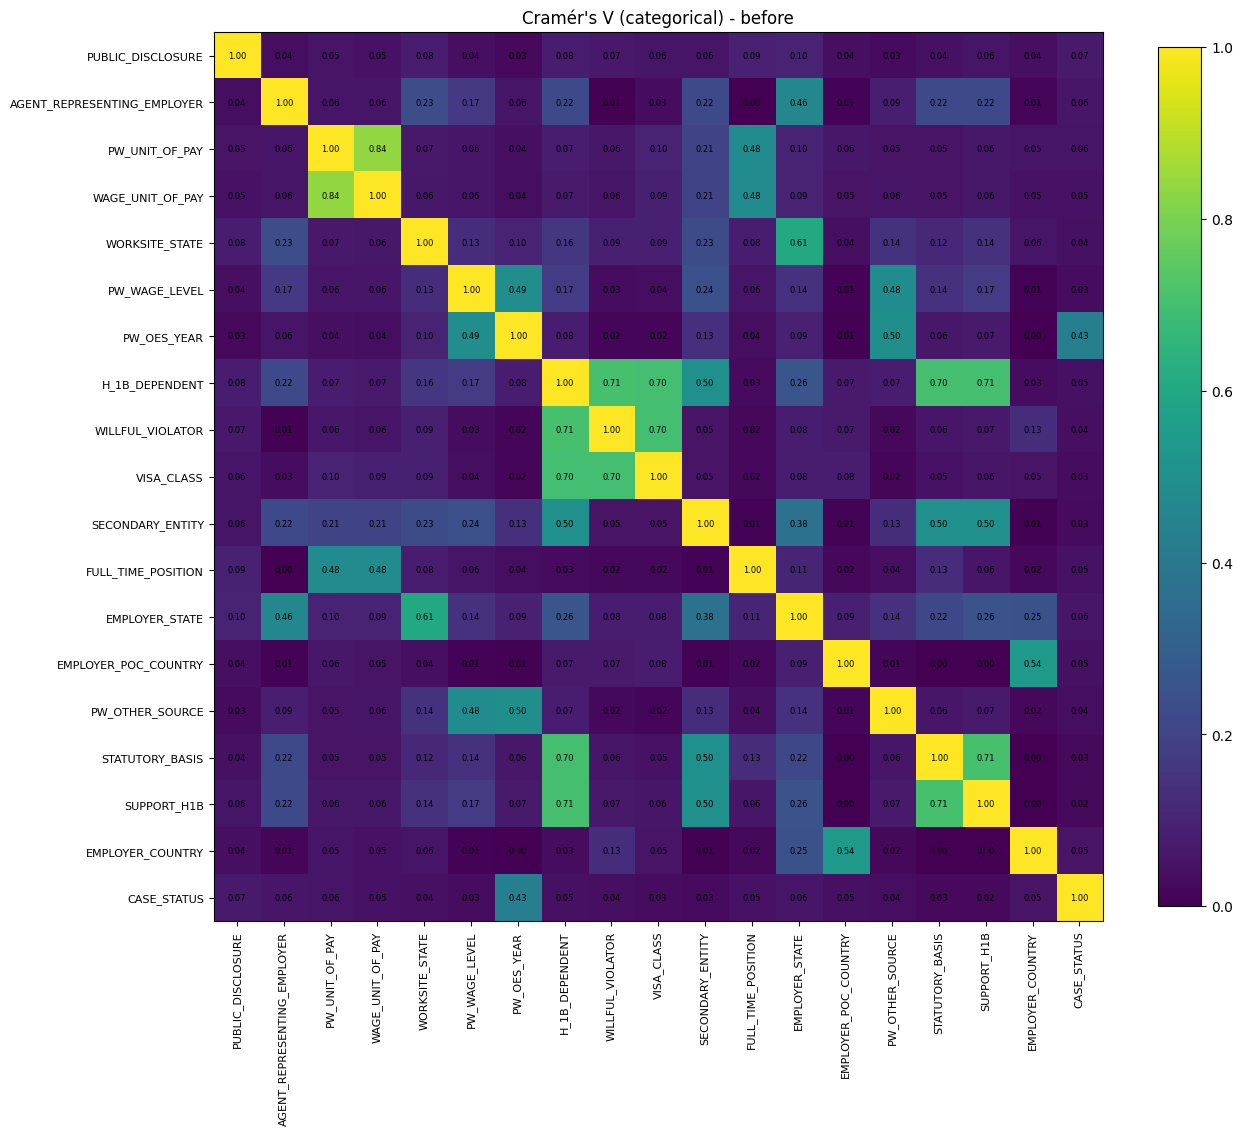


[before] numeric: Spearman with each CASE_STATUS class
                             CASE_STATUS=Certified  \
PREVAILING_WAGE                          0.087662   
WAGE_RATE_OF_PAY_TO                      0.064019   
WAGE_RATE_OF_PAY_FROM                    0.077307   
WORKSITE_WORKERS                         0.048596   
TOTAL_WORKER_POSITIONS                   0.048255   
NEW_CONCURRENT_EMPLOYMENT               -0.014792   
NEW_EMPLOYMENT                          -0.023366   
TOTAL_WORKSITE_LOCATIONS                 0.022739   
NAICS_CODE                              -0.038587   
AMENDED_PETITION                         0.035666   
CONTINUED_EMPLOYMENT                     0.030406   
CHANGE_PREVIOUS_EMPLOYMENT               0.023496   
CHANGE_EMPLOYER                         -0.019778   

                            CASE_STATUS=Certified - Withdrawn  \
PREVAILING_WAGE                                     -0.068331   
WAGE_RATE_OF_PAY_TO                                 -0.026374   
WAGE_

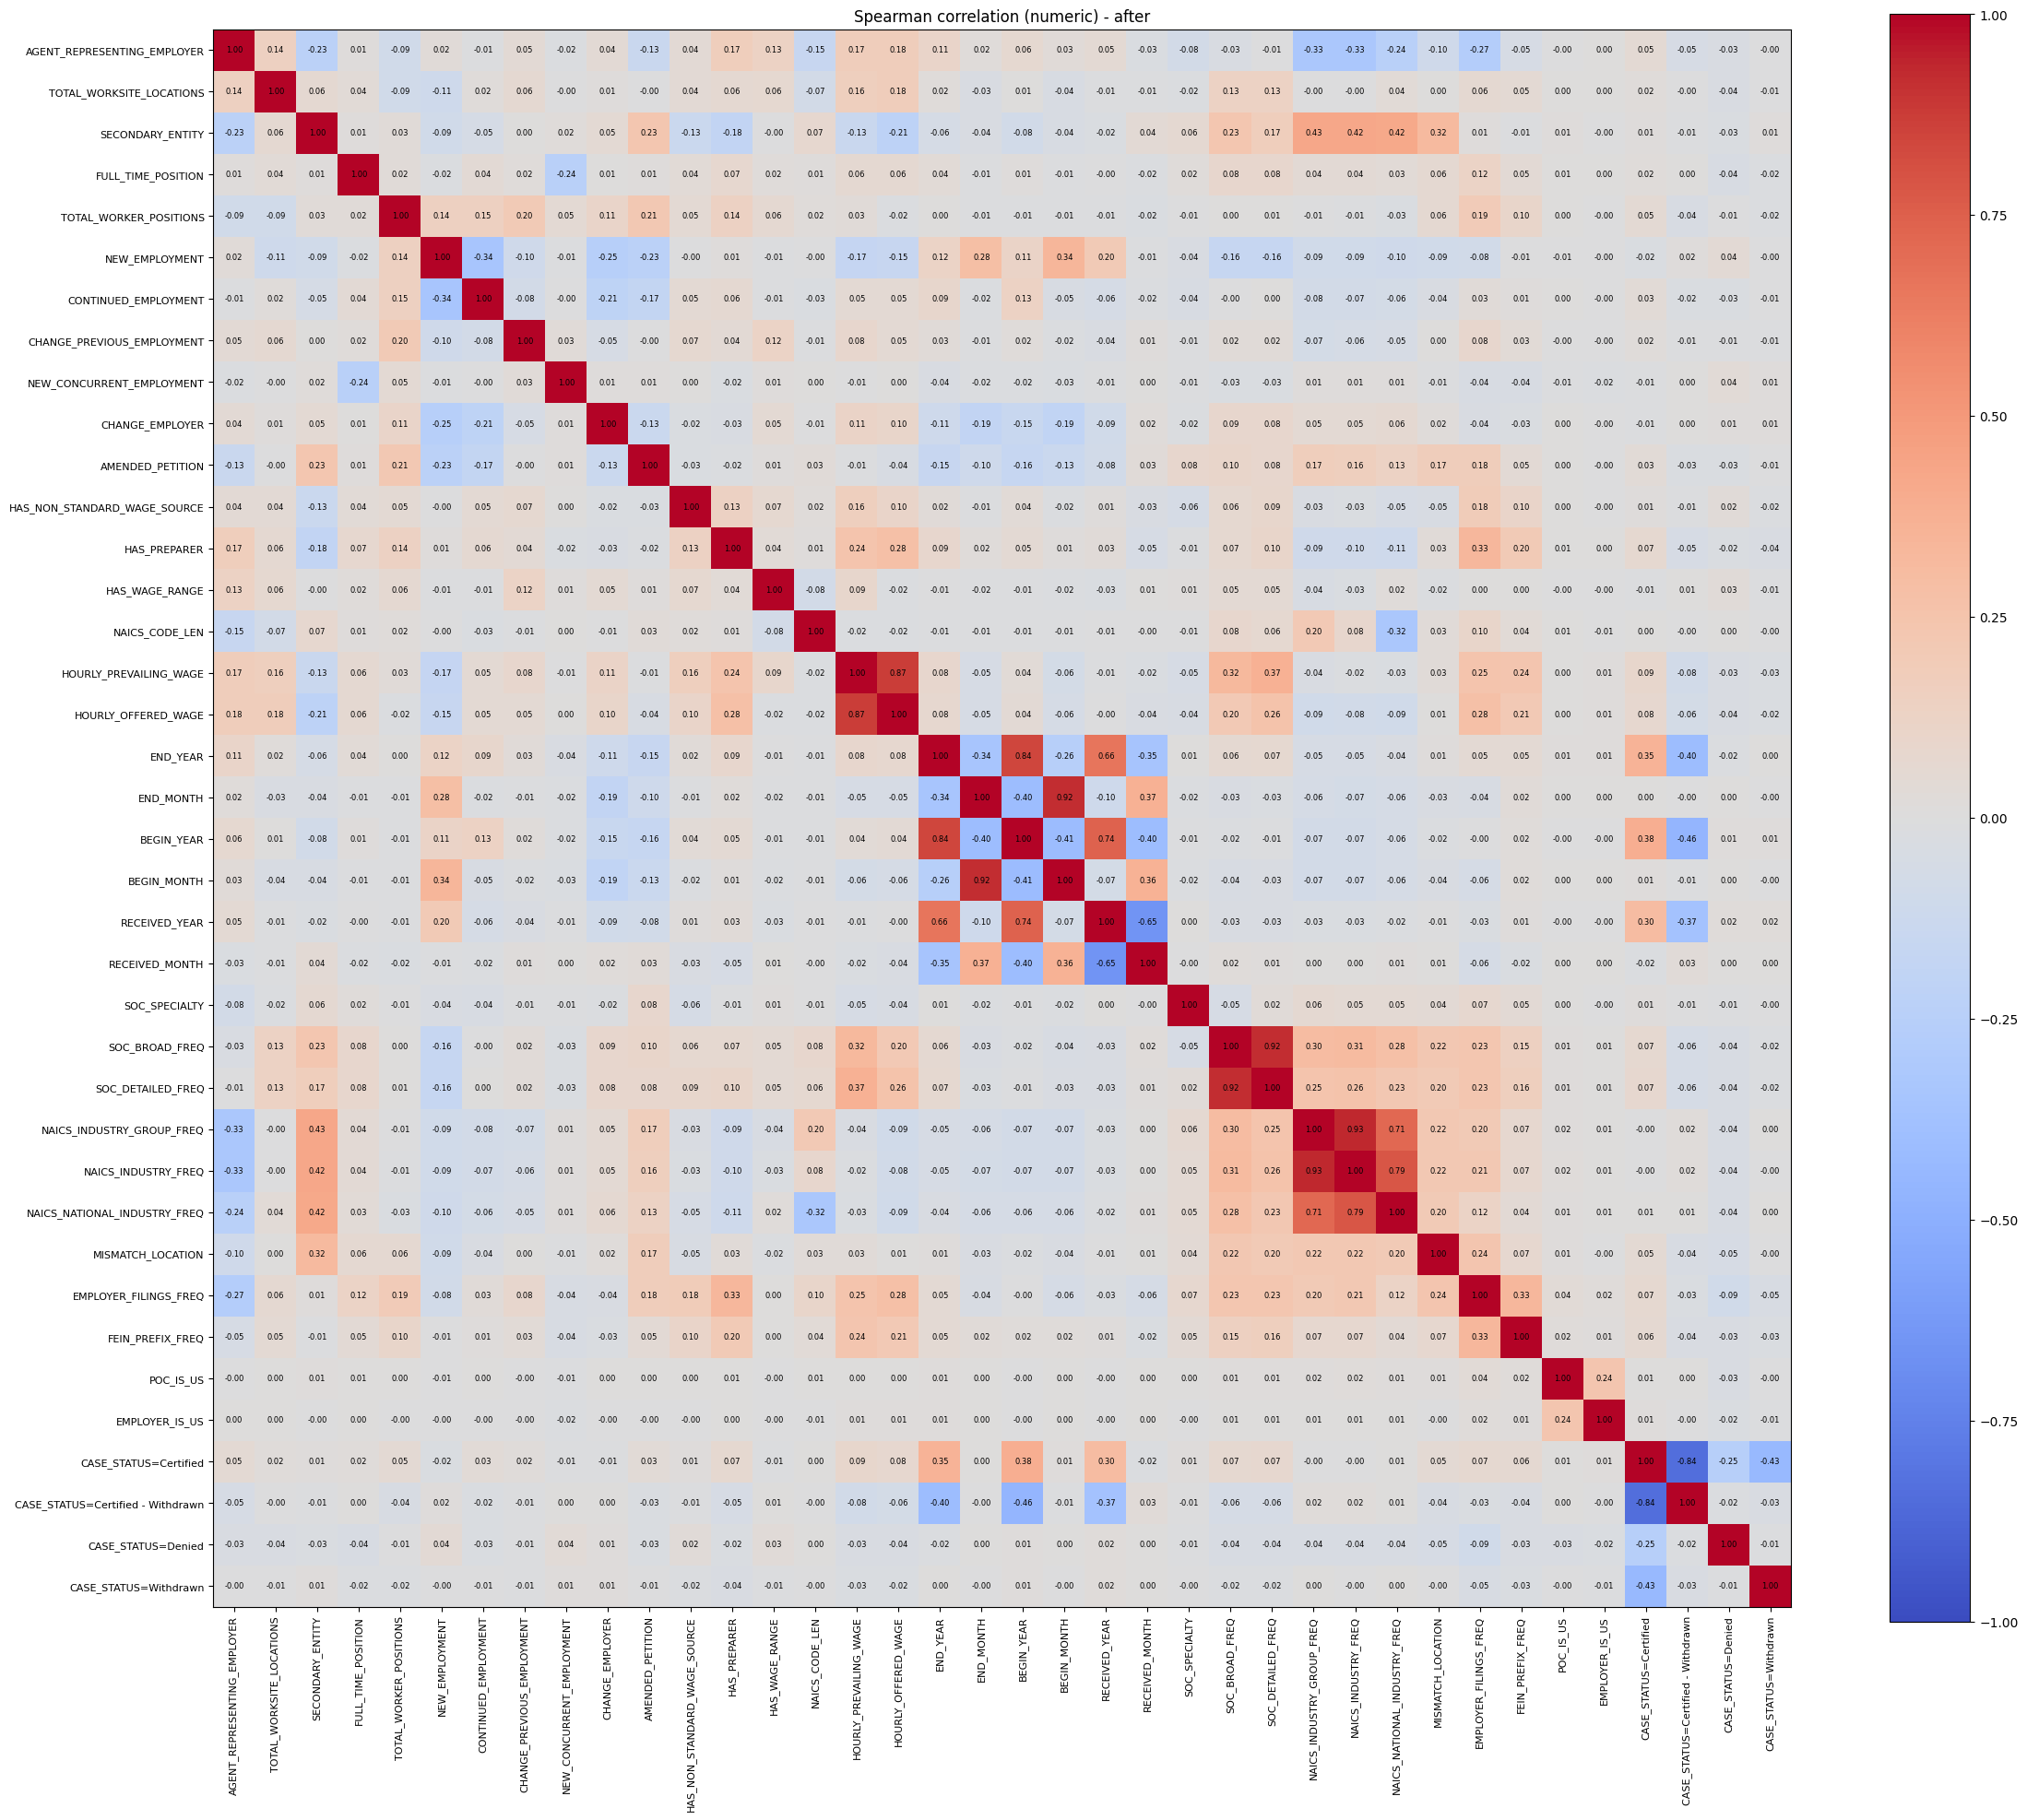

[after] no usable categorical columns

[after] numeric: Spearman with each CASE_STATUS class
                              CASE_STATUS=Certified  \
BEGIN_YEAR                                0.383555   
END_YEAR                                  0.351637   
RECEIVED_YEAR                             0.304037   
HOURLY_PREVAILING_WAGE                    0.091670   
EMPLOYER_FILINGS_FREQ                     0.068129   
HOURLY_OFFERED_WAGE                       0.077522   
SOC_DETAILED_FREQ                         0.072577   
SOC_BROAD_FREQ                            0.070301   
HAS_PREPARER                              0.068506   
FEIN_PREFIX_FREQ                          0.055320   
AGENT_REPRESENTING_EMPLOYER               0.053944   
MISMATCH_LOCATION                         0.053399   
TOTAL_WORKER_POSITIONS                    0.048571   
NAICS_INDUSTRY_FREQ                      -0.001153   
FULL_TIME_POSITION                        0.019819   

                             CASE_STATUS=

In [1]:
"""
Per-column check + CASE_STATUS (class) distribution for the kept LCA columns,
with a feature-cleaning step and correlation heatmaps before / after it,
and a one-hot encoding step at the end.

Usage:  set INPUT_PATH and OUTPUT_DIR below, then run: python column_class_dist.py
Outputs (in OUTPUT_DIR):
  heatmap_numeric_before.png / heatmap_numeric_after.png
  heatmap_categorical_before.png / heatmap_categorical_after.png
  corr_with_denied_<numeric|categorical>_<before|after>.csv
  summary.csv            one row per column (on the CLEANED data)
  dist_<COLUMN>.csv      CASE_STATUS counts + row % + denied rate per value
  dist_<COLUMN>_binned.csv  same for numeric / date columns after binning
"""
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.feature_extraction.text import TfidfVectorizer

# ---- EDIT THESE ----
INPUT_PATH = "/kaggle/input/datasets/malavms/lca-data/LCA_Disclosure_Data_FY2026_Q3.csv"  # .parquet also works
OUTPUT_DIR = "/kaggle/working/"
# --------------------

LABEL = "CASE_STATUS"
DENIED = "Denied"
MAX_LEVELS = 60         # columns with more unique values than this are binned or skipped
HEATMAP_SAMPLE = 200_000  # rows used for heatmaps (Cramér's V is O(cols^2) crosstabs); None = all
HEATMAP_MAX_CARD = 60    # categorical cols with more levels than this are left out of the heatmap
OHE_MAX_LEVELS = 60      # categorical cols with more levels than this are NOT one-hot encoded

KEEP = [
    "PUBLIC_DISCLOSURE", "AGENT_REPRESENTING_EMPLOYER", "TOTAL_WORKSITE_LOCATIONS",
    "PW_UNIT_OF_PAY", "PREVAILING_WAGE", "WAGE_UNIT_OF_PAY", "WAGE_RATE_OF_PAY_FROM",
    "WORKSITE_POSTAL_CODE", "WORKSITE_STATE", "PW_WAGE_LEVEL", "PW_OES_YEAR",
    "H_1B_DEPENDENT", "WILLFUL_VIOLATOR", "WORKSITE_COUNTY", "RECEIVED_DATE",
    "WORKSITE_CITY", "VISA_CLASS", "JOB_TITLE", "SOC_CODE", "SECONDARY_ENTITY",
    "FULL_TIME_POSITION", "BEGIN_DATE", "END_DATE", "TOTAL_WORKER_POSITIONS",
    "NEW_EMPLOYMENT", "CONTINUED_EMPLOYMENT", "CHANGE_PREVIOUS_EMPLOYMENT",
    "NEW_CONCURRENT_EMPLOYMENT", "CHANGE_EMPLOYER", "AMENDED_PETITION",
    "WORKSITE_WORKERS", "EMPLOYER_CITY", "EMPLOYER_STATE", "EMPLOYER_POSTAL_CODE",
    "NAICS_CODE", "EMPLOYER_POC_COUNTRY", "PW_OTHER_SOURCE", "STATUTORY_BASIS",
    "PREPARER_LAST_NAME", "WAGE_RATE_OF_PAY_TO", "SUPPORT_H1B","EMPLOYER_FEIN","EMPLOYER_COUNTRY"
    # add any further columns you kept here
]

unit_to_hours = {
    "Hour": 1,
    "Week": 40,
    "Bi-Weekly": 80,
    "Month": 2080 / 12,
    "Year": 2080
}

yn = {"YES": 1, "NO": 0, "Y": 1, "N": 0}





# ----------------------------------------------------------------------------
# Loading / helpers
# ----------------------------------------------------------------------------
def load(path: str) -> pd.DataFrame:
    p = Path(path)
    return pd.read_parquet(p) if p.suffix == ".parquet" else pd.read_csv(p, low_memory=False)


def crosstab_with_rate(col: pd.Series, y: pd.Series) -> pd.DataFrame:
    ct = pd.crosstab(col.fillna("<<MISSING>>"), y)
    classes = list(ct.columns)
    ct["n"] = ct[classes].sum(axis=1)
    ct["pct_of_rows"] = (ct["n"] / ct["n"].sum() * 100).round(2)
    for k in classes:                      # share of each CASE_STATUS class within this value
        ct[f"{k}_rate_%"] = (ct[k] / ct["n"] * 100).round(3)
    return ct.sort_values("n", ascending=False)

def soc_levels(df, col="SOC_CODE", drop_src=True):
    s = df[col].astype("string").str.strip()
    s = s.where(s.str.fullmatch(r"\d{2}-\d{4}(\.\d{2})?"))        # anything else -> NaN
    df["SOC_MAJOR"]    = s.str[:2].fillna("UNKNOWN")               # 15
    df["SOC_MINOR"]    = s.str[:4].fillna("UNKNOWN")               # 15-1
    df["SOC_BROAD"]    = s.str[:6].fillna("UNKNOWN")               # 15-125
    df["SOC_DETAILED"] = s.str[:7].fillna("UNKNOWN")               # 15-1252
    suf = s.str[8:]                                                # O*NET suffix: 00, 09, ...
    df["SOC_SPECIALTY"] = (suf.notna() & ~suf.isin(["", "00"])).astype("int8")
    return df.drop(columns=[col]) if drop_src else df


def to_number(s: pd.Series) -> pd.Series:
    """Strip $ , and spaces, then coerce to float. Handy for wage columns stored as text."""
    return pd.to_numeric(s.astype(str).str.replace(r"[$,\s]", "", regex=True), errors="coerce")

def naics_levels(df, col="NAICS_CODE", drop_src=True):
    s = df[col].astype("string").str.strip().str.replace(r"\.0$", "", regex=True)
    s = s.where(s.str.fullmatch(r"\d{2,6}"))
    df["NAICS_CODE_LEN"] = s.str.len().fillna(0).astype("int8")   # 0 = invalid/missing
    names = {2: "NAICS_SECTOR", 3: "NAICS_SUBSECTOR", 4: "NAICS_INDUSTRY_GROUP",
             5: "NAICS_INDUSTRY", 6: "NAICS_NATIONAL_INDUSTRY"}
    for k, name in names.items():
        df[name] = s.str[:k].where(s.str.len() >= k).fillna("UNKNOWN")
    df["NAICS_SECTOR"] = df["NAICS_SECTOR"].replace({"32": "31", "33": "31", "45": "44", "49": "48"})
    return df.drop(columns=[col]) if drop_src else df

# ----------------------------------------------------------------------------
# FEATURE CLEANING  <-- edit this
# ----------------------------------------------------------------------------
def clean_features(df: pd.DataFrame) -> pd.DataFrame:
    """Boilerplate cleaning. Takes the raw df (KEEP cols + LABEL), returns a cleaned copy.
    Fill in / delete the sections as you like. Keep LABEL in the output."""
    df = df.copy()

    # 1) Drop rows with no label / unwanted classes ------------------------------
    df = df[df[LABEL].notna()]
    # df = df[df[LABEL].isin(["Certified", "Denied"])]

    n0 = len(df)
    dup = df.duplicated()
    print(f"dropping {dup.sum()} exact duplicate rows:", df.loc[dup, LABEL].value_counts().to_dict())
    df = df[~dup]
    
    df["HAS_NON_STANDARD_WAGE_SOURCE"] = df["PW_OTHER_SOURCE"].apply(
        lambda x: 1 if pd.notna(x) and str(x).strip() != "" else 0
    )

    df["HAS_CLAIMED_EXEMPTION"] = df["STATUTORY_BASIS"].apply(
        lambda x: 1 if pd.notna(x) and str(x).strip() != "" else 0
    )

    df["HAS_PREPARER"] = df["PREPARER_LAST_NAME"].apply(
        lambda x: 1 if pd.notna(x) and str(x).strip() != "" else 0
    )

    df["HAS_WAGE_RANGE"] = df["WAGE_RATE_OF_PAY_TO"].apply(
        lambda x: 1 if pd.notna(x) and str(x).strip() != "" else 0
    )
    
    for c in ["SECONDARY_ENTITY", "FULL_TIME_POSITION", "AGENT_REPRESENTING_EMPLOYER"]:
        df[c] = (df[c].astype("string").str.strip().str.upper()
                   .map(yn).astype("Int8"))

    # df["WILLFUL_VIOLATOR"] = ( df["WILLFUL_VIOLATOR"].astype("string").str.strip().str.upper().fillna(0)
    #     .map({"Yes": 1, "No": 0})
    # )
    
    # df["H_1B_DEPENDENT"] = ( df["H_1B_DEPENDENT"].astype("string").str.strip().str.upper().fillna(0)
    #     .map({"Yes": 1, "No": 0})
    # )

    for col in ["WILLFUL_VIOLATOR", "H_1B_DEPENDENT", "SUPPORT_H1B"]:
        df[col] = (
            df[col]
            .astype("string")
            .str.strip()
            .str.upper()
            .fillna("UNKNOWN")
            .replace("", "UNKNOWN")
        )
    df = naics_levels(df)
    df["HOURLY_PREVAILING_WAGE"] = (
        df["PREVAILING_WAGE"] /
        df["PW_UNIT_OF_PAY"].map(unit_to_hours)
    )

    df["HOURLY_OFFERED_WAGE"] = (
        df["WAGE_RATE_OF_PAY_FROM"] /
        df["WAGE_UNIT_OF_PAY"].map(unit_to_hours)
    )

    WAGE_CAP = 1000   # $/hr; set from the check above
    n0 = len(df)
    bad = (
        (df["HOURLY_PREVAILING_WAGE"] > WAGE_CAP) | (df["HOURLY_OFFERED_WAGE"] > WAGE_CAP)
        | (df["HOURLY_PREVAILING_WAGE"] <= 0)     | (df["HOURLY_OFFERED_WAGE"] <= 0)
    )
    print(f"dropping {bad.sum()} rows with implausible wages:", df.loc[bad, LABEL].value_counts().to_dict())
    df = df[~bad]

    # df["NAICS_CODE"] = df["NAICS_CODE"].astype("string").str[:2]

    df["END_DATE"] = pd.to_datetime(df["END_DATE"], errors="coerce")
    df["BEGIN_DATE"] = pd.to_datetime(df["BEGIN_DATE"], errors="coerce")
    df["RECEIVED_DATE"] = pd.to_datetime(df["RECEIVED_DATE"], errors="coerce")
    
    df["END_YEAR"] = df["END_DATE"].dt.year
    df["END_MONTH"] = df["END_DATE"].dt.month

    df["PW_WAGE_LEVEL"] = df["PW_WAGE_LEVEL"].fillna("UNKNOWN")
    df["PUBLIC_DISCLOSURE"] = df["PUBLIC_DISCLOSURE"].fillna("UNKNOWN")
    df["EMPLOYER_STATE"] = df["EMPLOYER_STATE"].fillna("UNKNOWN")
    
    df["BEGIN_YEAR"] = df["BEGIN_DATE"].dt.year
    df["BEGIN_MONTH"] = df["BEGIN_DATE"].dt.month

    df["RECEIVED_YEAR"] = df["RECEIVED_DATE"].dt.year
    df["RECEIVED_MONTH"] = df["RECEIVED_DATE"].dt.month
    
    df = ohe_col(df, "PUBLIC_DISCLOSURE")
    df = ohe_col(df, "EMPLOYER_STATE")
    # df = ohe_col(df, "EMPLOYER_POC_COUNTRY")
    df = ohe_col(df, "VISA_CLASS")
    # df = ohe_col(df, "PW_OES_YEAR")
    df = ohe_col(df, "PW_WAGE_LEVEL")
    df = ohe_col(df, "WORKSITE_STATE")
    df = ohe_col(df, "WILLFUL_VIOLATOR")
    df = ohe_col(df, "H_1B_DEPENDENT")
    df = ohe_col(df, "SUPPORT_H1B")
    # df = ohe_col(df, "SECTOR_REPRESENTATION")

    df = soc_levels(df)
    df = ohe_col(df, "SOC_MAJOR")
    top = df["SOC_MINOR"].value_counts().head(30).index
    df = ohe_col(df, "SOC_MINOR", keep_levels=top)
    for c in ["SOC_BROAD", "SOC_DETAILED"]:
        df[c + "_FREQ"] = df[c].map(df[c].value_counts(normalize=True)).astype("float32")
        df = df.drop(columns=[c])

    df = ohe_col(df, "NAICS_SECTOR")
    top = df["NAICS_SUBSECTOR"].value_counts().head(30).index
    df = ohe_col(df, "NAICS_SUBSECTOR", keep_levels=top)
    
    for c in ["NAICS_INDUSTRY_GROUP", "NAICS_INDUSTRY", "NAICS_NATIONAL_INDUSTRY"]:
        df[c + "_FREQ"] = df[c].map(df[c].value_counts(normalize=True)).astype("float32")
        df = df.drop(columns=[c])

    text_cols = [c for c in ["WORKSITE_STATE", "WORKSITE_CITY", "EMPLOYER_STATE",
                             "EMPLOYER_CITY", "JOB_TITLE"] if c in df.columns]
    for c in text_cols:
        df[c] = df[c].astype("string").str.strip().str.upper()

    df["MISMATCH_LOCATION"] = (
        (
            df["EMPLOYER_CITY"].astype("string").str.strip().str.upper()
            != df["WORKSITE_CITY"].astype("string").str.strip().str.upper()
        )
        |
        (
            df["EMPLOYER_POSTAL_CODE"].astype("string").str.strip()
            != df["WORKSITE_POSTAL_CODE"].astype("string").str.strip()
        )
    ).astype(int)

    fein = df["EMPLOYER_FEIN"].astype("string").str.replace(r"\D", "", regex=True)   # "27-2387291" -> "272387291"
    fein = fein.where(fein.str.len() == 9)                                           # bad values -> NaN

    # group key for the split (keep it, but never use it as a model feature)
    df["FEIN_ID"] = fein.fillna(pd.Series("NOFEIN_" + df.index.astype(str), index=df.index))

    df["EMPLOYER_FILINGS_FREQ"] = fein.map(fein.value_counts(normalize=True)).fillna(0).astype("float32")

    prefix = fein.str[:2].fillna("UNKNOWN")                                          # ~90 levels: too many to one-hot
    df["FEIN_PREFIX_FREQ"] = prefix.map(prefix.value_counts(normalize=True)).astype("float32")


    tfidf = TfidfVectorizer(max_features=150, ngram_range=(1, 2), min_df=50,
                            stop_words="english", sublinear_tf=True, dtype=np.float32)
    X = tfidf.fit_transform(df["JOB_TITLE"].fillna("").astype(str))
    title_df = pd.DataFrame(X.toarray(), index=df.index,
                            columns=["TITLE_" + t.replace(" ", "_") for t in tfidf.get_feature_names_out()])
    df = pd.concat([df, title_df], axis=1)
    US = ["US","U.S.","USA","U.S.A.","UNITED STATES","UNITED STATES OF AMERICA"]
    df["POC_IS_US"] = (
        df["EMPLOYER_POC_COUNTRY"]
        .astype("string")
        .str.strip()
        .str.upper()
        .isin(US)
        .astype("int8")
    )
    df["EMPLOYER_IS_US"] = (
        df["EMPLOYER_COUNTRY"]
        .astype("string")
        .str.strip()
        .str.upper()
        .isin(US)
        .astype("int8")
    )
    
    # 2) Drop columns (constant, leaky, useless, too sparse) ----------------------
    drop_cols = [
        "PW_OTHER_SOURCE", "STATUTORY_BASIS", "PREPARER_LAST_NAME", "WAGE_RATE_OF_PAY_TO", "PW_UNIT_OF_PAY", "WAGE_UNIT_OF_PAY","WAGE_RATE_OF_PAY_FROM","PREVAILING_WAGE",
        "END_DATE","BEGIN_DATE","PW_OES_YEAR","NAICS_CODE", "EMPLOYER_POC_COUNTRY","RECEIVED_DATE","EMPLOYER_CITY","WORKSITE_POSTAL_CODE","EMPLOYER_POSTAL_CODE","WORKSITE_COUNTY","WORKSITE_CITY", "JOB_TITLE",
        "EMPLOYER_FEIN", "WORKSITE_WORKERS", "HAS_CLAIMED_EXEMPTION", "EMPLOYER_COUNTRY" 
    ]
    df = df.drop(columns=[c for c in drop_cols if c in df.columns])

    # 3) Standardise text (strip, upper-case) ------------------------------------
    

    # 4) Numeric coercion (wages etc. that may be strings with $ or commas) -------
    num_cols = [c for c in ["PREVAILING_WAGE", "WAGE_RATE_OF_PAY_FROM", "WAGE_RATE_OF_PAY_TO",
                            "TOTAL_WORKER_POSITIONS", "TOTAL_WORKSITE_LOCATIONS",
                            "WORKSITE_WORKERS", "PW_OES_YEAR"] if c in df.columns]
    for c in num_cols:
        df[c] = to_number(df[c])

    # 5) Annualise wages (needs the *_UNIT_OF_PAY cols) --------------------------
    # mult = {"Year": 1, "Month": 12, "Bi-Weekly": 26, "Week": 52, "Hour": 2080}
    # df["WAGE_FROM_ANNUAL"] = df["WAGE_RATE_OF_PAY_FROM"] * df["WAGE_UNIT_OF_PAY"].map(mult)
    # df["PW_ANNUAL"]        = df["PREVAILING_WAGE"]       * df["PW_UNIT_OF_PAY"].map(mult)

    # 6) Dates -> durations / parts ----------------------------------------------
    for c in ["RECEIVED_DATE", "BEGIN_DATE", "END_DATE"]:
        if c in df.columns:
            df[c] = pd.to_datetime(df[c], errors="coerce")
    # if {"BEGIN_DATE", "END_DATE"} <= set(df.columns):
    #     df["EMPLOYMENT_DAYS"] = (df["END_DATE"] - df["BEGIN_DATE"]).dt.days
    # if {"RECEIVED_DATE", "BEGIN_DATE"} <= set(df.columns):
    #     df["LEAD_DAYS"] = (df["BEGIN_DATE"] - df["RECEIVED_DATE"]).dt.days

    # 7) Outliers / impossible values --------------------------------------------
    # for c in num_cols:
    #     lo, hi = df[c].quantile([0.001, 0.999])
    #     df[c] = df[c].clip(lo, hi)

    # 8) Missing values -----------------------------------------------------------
    # df[num_cols] = df[num_cols].fillna(df[num_cols].median())
    # cat_cols = df.select_dtypes(include=["object", "string"]).columns.drop(LABEL, errors="ignore")
    # df[cat_cols] = df[cat_cols].fillna("<<MISSING>>")

    # 9) Collapse rare categories -------------------------------------------------
    # for c in ["WORKSITE_STATE", "SOC_CODE"]:
    #     if c in df.columns:
    #         top = df[c].value_counts().head(30).index
    #         df[c] = df[c].where(df[c].isin(top), "OTHER")

    # 10) Y/N flags -> 0/1 --------------------------------------------------------
    # yn = {"Y": 1, "N": 0}
    # for c in ["FULL_TIME_POSITION", "H_1B_DEPENDENT", "WILLFUL_VIOLATOR", "AMENDED_PETITION"]:
    #     if c in df.columns:
    #         df[c] = df[c].map(yn)

    # 11) One-hot encode, one column at a time ------------------------------------
    # df = ohe_col(df, "WORKSITE_STATE")
    # df = ohe_col(df, "PW_WAGE_LEVEL", drop_first=True)
    # df = ohe_col(df, "WAGE_UNIT_OF_PAY")
    # df = ohe_col(df, "has_preparer")

    return df


# ----------------------------------------------------------------------------
# ONE-HOT ENCODING
# ----------------------------------------------------------------------------
def ohe_col(df: pd.DataFrame, col: str, max_levels: int = OHE_MAX_LEVELS,
            drop_first: bool = False, keep_levels=None) -> pd.DataFrame:
    """One-hot encode a SINGLE column and return df with that column replaced by dummies
    named  COL=value.  Use it directly inside clean_features:

        df = ohe_col(df, "WORKSITE_STATE")
        df = ohe_col(df, "PW_WAGE_LEVEL", drop_first=True)

    max_levels  : if the column has more unique values than this, it is left untouched
                  (and a message is printed) so you don't explode the width.
    drop_first  : drop one dummy (use for linear/logistic models).
    keep_levels : optional list of levels to encode; everything else goes to "OTHER".
                  Use the same list on train and test to keep columns identical.

    NaN becomes its own "<<MISSING>>" level. Dummies are int8.
    """
    if col not in df.columns:
        print(f"[ohe_col] {col} not found, skipped")
        return df
    n = df[col].nunique(dropna=True)
    if keep_levels is None and n > max_levels:
        print(f"[ohe_col] {col} skipped ({n} levels > {max_levels})")
        return df

    s = df[col].astype("object").where(df[col].notna(), "<<MISSING>>").astype(str)
    if keep_levels is not None:
        s = s.where(s.isin(list(keep_levels) + ["<<MISSING>>"]), "OTHER")
    dummies = pd.get_dummies(s, prefix=col, prefix_sep="=", drop_first=drop_first, dtype=np.int8)
    return pd.concat([df.drop(columns=[col]), dummies], axis=1)


#----------------------------------------------------------------------------
# Correlation / association heatmaps
# ----------------------------------------------------------------------------
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return np.nan
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    phi2c = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1); kc = k - (k - 1) ** 2 / (n - 1)
    d = min(kc - 1, rc - 1)
    return np.sqrt(phi2c / d) if d > 0 else np.nan
 
 
def plot_heatmap(mat, title, save_path=None, vmin=-1, vmax=1, cmap="coolwarm"):
    n = len(mat)
    fig, ax = plt.subplots(figsize=(max(7, .55 * n + 3), max(6, .55 * n + 2)))
    im = ax.imshow(mat.values, vmin=vmin, vmax=vmax, cmap=cmap)
    ax.set_xticks(range(n)); ax.set_xticklabels(mat.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(n)); ax.set_yticklabels(mat.index, fontsize=8)
    for i in range(n):
        for j in range(n):
            if not np.isnan(mat.values[i, j]):
                ax.text(j, i, f"{mat.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
    fig.colorbar(im, ax=ax, shrink=.8); ax.set_title(title); fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150)
    plt.show()
 
 
def numeric_corr_heatmap(df, num_cols, tag, out):
    num_cols = [c for c in num_cols if df[c].notna().sum() > 1 and df[c].nunique() > 1]
    if not num_cols:
        print(f"[{tag}] no usable numeric columns"); return None
    # CASE_STATUS is nominal, so correlate each feature with one 0/1 column per class
    ind = pd.get_dummies(df[LABEL].astype(str), prefix=LABEL, prefix_sep="=", dtype=np.int8)
    d = pd.concat([df[num_cols], ind], axis=1)
    sp = d.corr(method="spearman")
    plot_heatmap(sp, f"Spearman correlation (numeric) - {tag}", out / f"heatmap_numeric_{tag}.png")
    r = sp.loc[num_cols, list(ind.columns)]                       # feature x class
    r = r.loc[r.abs().max(axis=1).sort_values(ascending=False).index]
    r.to_csv(out / f"corr_with_status_numeric_{tag}.csv")
    return r
 
 
def categorical_assoc_heatmap(df, cat_cols, tag, out):
    cat_cols = [c for c in cat_cols if 1 < df[c].nunique(dropna=True) <= HEATMAP_MAX_CARD]
    if not cat_cols:
        print(f"[{tag}] no usable categorical columns"); return None
    c = df[cat_cols].astype("object").fillna("<<MISSING>>")
    c[LABEL] = df[LABEL].astype(str)
    names = list(c.columns)
    cv = pd.DataFrame(np.nan, index=names, columns=names)
    for i, a in enumerate(names):
        for b in names[i:]:
            cv.loc[a, b] = cv.loc[b, a] = 1.0 if a == b else cramers_v(c[a], c[b])
    plot_heatmap(cv, f"Cramér's V (categorical) - {tag}",
                 out / f"heatmap_categorical_{tag}.png", vmin=0, vmax=1, cmap="viridis")
    r = cv[LABEL].drop(LABEL).sort_values(ascending=False)
    r.to_csv(out / f"corr_with_status_categorical_{tag}.csv", header=["cramers_v"])
    return r
 
 
def run_heatmaps(df, tag, out):
    """Both heatmaps for the current state of df. Column types are re-detected each time,
    so columns you add/convert in clean_features show up in the right heatmap."""
    d = df.sample(HEATMAP_SAMPLE, random_state=0) if HEATMAP_SAMPLE and len(df) > HEATMAP_SAMPLE else df
    # feats = [c for c in d.columns if c != LABEL]
    feats = [c for c in d.columns if c != LABEL and "=" not in c and not c.startswith("TITLE_")]
    # feats = [c for c in d.columns if c != LABEL and not c.startswith("TITLE_")]
    num_cols = [c for c in feats if pd.api.types.is_numeric_dtype(d[c]) and not pd.api.types.is_bool_dtype(d[c])]
    cat_cols = [c for c in feats if c not in num_cols and not pd.api.types.is_datetime64_any_dtype(d[c])]
    print(f"\n[{tag}] {len(num_cols)} numeric cols, {len(cat_cols)} categorical cols")
    num_r = numeric_corr_heatmap(d, num_cols, tag, out)
    cat_r = categorical_assoc_heatmap(d, cat_cols, tag, out)
    if num_r is not None:
        print(f"\n[{tag}] numeric: Spearman with each CASE_STATUS class\n", num_r.head(15))
    if cat_r is not None:
        print(f"\n[{tag}] categorical: Cramér's V with CASE_STATUS\n", cat_r.head(15))
 
 
# ----------------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------------
def main(path: str) -> None:
    df = load(path)
    out = Path(OUTPUT_DIR)
    out.mkdir(parents=True, exist_ok=True)
 
    print("shape:", df.shape)
    print("\nOverall class distribution:")
    overall = df[LABEL].value_counts(dropna=False)
    print(pd.concat([overall, (overall / len(df) * 100).round(3)], axis=1, keys=["n", "%"]))
 
    missing_cols = [c for c in KEEP if c not in df.columns]
    if missing_cols:
        print("\nNOT FOUND in file (check spelling):", missing_cols)
    cols = [c for c in KEEP if c in df.columns]
    df = df[cols + [LABEL]]
 
    # ---- BEFORE cleaning ----
    run_heatmaps(df, "before", out)
    print("rows before:", len(df), "| kept cols:", df.shape[1] - 1)
    print("label missing:", int(df[LABEL].isna().sum()))
    print("missing cells before (kept cols):", int(df.drop(columns=[LABEL]).isna().sum().sum()))
    print("duplicate rows before:", int(df.duplicated().sum()))
    # ---- cleaning ----
    df = clean_features(df)
    print("\nshape after cleaning:", df.shape)
    
    for c in ["HOURLY_PREVAILING_WAGE", "HOURLY_OFFERED_WAGE"]:
        s = df[c]
        q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((s < lo) | (s > hi)).sum())
        print(f"{c}: fence [{lo:.2f}, {hi:.2f}] | outliers {n_out} ({n_out/len(s)*100:.1f}%) | max {s.max():.2f}")
    H = ["HOURLY_PREVAILING_WAGE", "HOURLY_OFFERED_WAGE"]
    for cap in [300, 500, 1000, 5000]:
        bad = (df[H] > cap).any(axis=1) | (df[H] <= 0).any(axis=1)
        print(f"cap ${cap}/hr: {bad.sum()} rows |", df.loc[bad, LABEL].value_counts().to_dict())
    # ---- AFTER cleaning ----
    run_heatmaps(df, "after", out)
    print("missing cells after:", int(df.isna().sum().sum()))
    print("duplicate rows after:", int(df.drop(columns=["FEIN_ID"]).duplicated().sum()))
    unk = [c for c in df.columns if c.endswith("=UNKNOWN")]
    print("UNKNOWN cells after cleaning:", int(df[unk].sum().sum()), "| columns:", unk)

    # ---- per-column report (on cleaned data) ----
    cols = [c for c in df.columns if c != LABEL]
    y = df[LABEL]
    rows = []
    for c in cols:
        s = df[c]
        vc = s.value_counts(dropna=True)
        rows.append({
            "column": c,
            "dtype": str(s.dtype),
            "missing_n": int(s.isna().sum()),
            "missing_%": round(s.isna().mean() * 100, 2),
            "n_unique": int(s.nunique(dropna=True)),
            "top_values": "; ".join(f"{k} ({v})" for k, v in vc.head(5).items()),
        })
 
        # low-cardinality: full class distribution per value
        if s.nunique(dropna=True) <= MAX_LEVELS:
            crosstab_with_rate(s, y).to_csv(out / f"dist_{c}.csv")
            continue
 
        # numeric: 10 quantile bins
        if pd.api.types.is_numeric_dtype(s):
            binned = pd.qcut(s, 10, duplicates="drop").astype(str)
            binned[s.isna()] = "<<MISSING>>"
            crosstab_with_rate(binned, y).to_csv(out / f"dist_{c}_binned.csv")
        # dates: by year-month
        elif "DATE" in c:
            d = pd.to_datetime(s, errors="coerce")
            ym = d.dt.to_period("M").astype(str)
            ym[d.isna()] = "<<MISSING>>"
            crosstab_with_rate(ym, y).sort_index().to_csv(out / f"dist_{c}_binned.csv")
        # high-cardinality text: top 30 levels only
        else:
            top = vc.head(30).index
            sub = df[s.isin(top)]
            crosstab_with_rate(sub[c], sub[LABEL]).to_csv(out / f"dist_{c}_top30.csv")
 
    summary = pd.DataFrame(rows)
    summary.to_csv(out / "summary.csv", index=False)
    with pd.option_context("display.max_rows", None, "display.width", 200, "display.max_colwidth", 60):
        print("\n", summary)
    print(f"\nWrote reports to {out.resolve()}")
 
    return df
 
 
if __name__ == "__main__":
    main(INPUT_PATH)

## Load and prepare the source data

Load the raw CSV, keep the selected columns that are present, and apply the cleaning and feature-encoding function. The printed shape and employer count are the first checks that the expected data and preparation ran. Compare the resulting row count with the documented final run before interpreting downstream results.

In [2]:
raw = load(INPUT_PATH)                      # read the 437,496-row file
cols = [c for c in KEEP if c in raw.columns]   # the columns you chose to keep
df = clean_features(raw[cols + [LABEL]])    # run your cleaning and encoding
print(df.shape, df["FEIN_ID"].nunique())    # rows, columns and number of employers

dropping 9423 exact duplicate rows: {'Certified': 8668, 'Certified - Withdrawn': 625, 'Withdrawn': 110, 'Denied': 20}
dropping 474 rows with implausible wages: {'Certified': 346, 'Denied': 54, 'Certified - Withdrawn': 50, 'Withdrawn': 24}
(427599, 430) 55191


## Raw-file figures quoted in the report

Print the missing-value shares, unique-value counts, largest hourly wage and other raw-file figures used in Sections 1-3 of the report, so each one can be traced to an output.

In [3]:
# Raw-file figures quoted in Sections 1-3 of the report
def blank(c):
    return raw[c].isna() | raw[c].astype(str).str.strip().eq("")

print("raw shape:", raw.shape, "| rows with no CASE_STATUS:", int(raw[LABEL].isna().sum()))
for c in ["PW_OTHER_SOURCE", "STATUTORY_BASIS", "WAGE_RATE_OF_PAY_TO", "PREPARER_LAST_NAME",
          "PW_WAGE_LEVEL", "H_1B_DEPENDENT", "WILLFUL_VIOLATOR", "SUPPORT_H1B"]:
    print(f"missing {c}: {blank(c).mean() * 100:.1f}%")
for c in ["WORKSITE_CITY", "EMPLOYER_CITY", "WORKSITE_POSTAL_CODE", "EMPLOYER_POSTAL_CODE", "NAICS_CODE", "SOC_CODE"]:
    print(f"unique {c}: {raw[c].nunique():,}")
US = ["US", "U.S.", "USA", "U.S.A.", "UNITED STATES", "UNITED STATES OF AMERICA"]
for c in ["EMPLOYER_POC_COUNTRY", "EMPLOYER_COUNTRY"]:
    print(f"{c} is the U.S.: {raw[c].astype(str).str.strip().str.upper().isin(US).mean() * 100:.1f}%")
hp = to_number(raw["PREVAILING_WAGE"]) / raw["PW_UNIT_OF_PAY"].map(unit_to_hours)
ho = to_number(raw["WAGE_RATE_OF_PAY_FROM"]) / raw["WAGE_UNIT_OF_PAY"].map(unit_to_hours)
print(f"largest hourly wage in the raw file: ${max(hp.max(), ho.max()):,.0f}")
w = df[["HOURLY_PREVAILING_WAGE", "HOURLY_OFFERED_WAGE"]]
q1, q3 = w.quantile(0.25), w.quantile(0.75)
outside = ((w < q1 - 1.5 * (q3 - q1)) | (w > q3 + 1.5 * (q3 - q1))).any(axis=1)
print(f"prepared rows outside the IQR fence on either wage: {int(outside.sum()):,}")
print("applications by received year:",
      pd.to_datetime(raw["RECEIVED_DATE"], errors="coerce").dt.year.astype("Int64").value_counts().sort_index().to_dict())
print("earliest decision date by status:",
      pd.to_datetime(raw["DECISION_DATE"], errors="coerce").groupby(raw[LABEL]).min().dt.date.to_dict())

raw shape: (437496, 98) | rows with no CASE_STATUS: 0
missing PW_OTHER_SOURCE: 90.3%
missing STATUTORY_BASIS: 77.8%
missing WAGE_RATE_OF_PAY_TO: 69.1%
missing PREPARER_LAST_NAME: 48.7%
missing PW_WAGE_LEVEL: 10.3%
missing H_1B_DEPENDENT: 2.4%
missing WILLFUL_VIOLATOR: 2.4%
missing SUPPORT_H1B: 77.7%
unique WORKSITE_CITY: 10,393
unique EMPLOYER_CITY: 6,837
unique WORKSITE_POSTAL_CODE: 13,491
unique EMPLOYER_POSTAL_CODE: 10,355
unique NAICS_CODE: 1,827
unique SOC_CODE: 845
EMPLOYER_POC_COUNTRY is the U.S.: 99.9%
EMPLOYER_COUNTRY is the U.S.: 100.0%
largest hourly wage in the raw file: $534,188
prepared rows outside the IQR fence on either wage: 17,699
applications by received year: {np.int64(2021): 106, np.int64(2022): 588, np.int64(2023): 4146, np.int64(2024): 5858, np.int64(2025): 92141, np.int64(2026): 334657}
earliest decision date by status: {'Certified': datetime.date(2025, 10, 1), 'Certified - Withdrawn': datetime.date(2025, 10, 1), 'Denied': datetime.date(2025, 11, 3), 'Withdrawn

## Split employers into exploration and confirmation halves

Group applications by employer (`FEIN_ID`), stratify employers by filing volume, and use seed 558 to assign each employer to one half while balancing row counts. Keeping each employer in only one half reduces leakage between exploration and confirmation. The TF-IDF vocabulary, the frequency encodings and the title-similarity feature were computed on all rows before the split; none of them uses the outcome.

In [4]:
import numpy as np, pandas as pd

SEED = 558                                   # the seed you will record
emp = df.groupby("FEIN_ID").size().rename("n").reset_index()   # applications per employer
emp["bucket"] = pd.cut(emp["n"], [0, 1, 5, 50, 500, np.inf],
                       labels=["1", "2-5", "6-50", "51-500", "501+"])  # volume group
rng = np.random.default_rng(SEED)            # the seeded random generator
side = {}                                    # employer -> half
for b, g in emp.groupby("bucket", observed=True):
    if b in ("51-500", "501+"):              # big employers: biggest first, they alternate
        g = g.sort_values(["n", "FEIN_ID"], ascending=[False, True])
    else:                                    # smaller ones: shuffled
        g = g.iloc[rng.permutation(len(g))]
    rows = {"exploration": 0, "confirmation": 0}   # row count per half in this group
    for fein, n in zip(g["FEIN_ID"], g["n"]):
        if rows["exploration"] == rows["confirmation"]:
            s = "exploration" if rng.random() < 0.5 else "confirmation"   # tie: coin flip
        else:
            s = min(rows, key=rows.get)      # otherwise the half with fewer rows
        side[fein] = s
        rows[s] += n
df["half"] = df["FEIN_ID"].map(side)         # tag every row with its half
explore = df[df["half"] == "exploration"]
confirm = df[df["half"] == "confirmation"]

## Verify the employer split

Assert that no employer appears in both halves, then print each half’s row count and case-status distribution. A failed assertion means the split should not be used for the planned confirmation analysis.

In [5]:
assert set(explore["FEIN_ID"]).isdisjoint(confirm["FEIN_ID"])   # no employer in both
print(len(explore), len(confirm))                                # rows, about 50/50
print(explore["CASE_STATUS"].value_counts())                     # class counts
print(confirm["CASE_STATUS"].value_counts())

213867 213732
CASE_STATUS
Certified                195692
Certified - Withdrawn     13245
Withdrawn                  3673
Denied                     1257
Name: count, dtype: int64
CASE_STATUS
Certified                196706
Certified - Withdrawn     12383
Withdrawn                  3417
Denied                     1226
Name: count, dtype: int64


## Construct prior certified-application history

For each employer, count certified applications decided before the current application was received. This creates `prior_certified`, the basis for the `has_history` comparison. It is a file-limited measure: applications before the dataset’s coverage period are not observed.

In [6]:
h = raw.loc[df.index, ["RECEIVED_DATE", "DECISION_DATE", "CASE_STATUS"]].copy()
h["rec"] = pd.to_datetime(h["RECEIVED_DATE"], errors="coerce")
h["dec"] = pd.to_datetime(h["DECISION_DATE"], errors="coerce")
h["cert"] = h["CASE_STATUS"].isin(["Certified", "Certified - Withdrawn"])
h["fein_id"] = df["FEIN_ID"]
prior = pd.Series(0, index=h.index)
for fein, g in h.groupby("fein_id"):
    if len(g) < 2: continue
    d = np.sort(g.loc[g["cert"], "dec"].dropna().values)
    prior.loc[g.index] = np.searchsorted(d, g["rec"].values, side="left")
df["prior_certified"] = prior

e = df[df["half"] == "exploration"].copy()
e["not_cert"] = e["CASE_STATUS"].isin(["Withdrawn", "Denied"]).astype(int)
e["has_history"] = (e["prior_certified"] >= 1).astype(int)
t = e.groupby("has_history")["not_cert"].agg(rows="size", not_certified="sum")
t["rate_%"] = (t["not_certified"] / t["rows"] * 100).round(2); print(t)

               rows  not_certified  rate_%
has_history                               
0             48882           2139    4.38
1            164985           2791    1.69


## Define the outcome and analysis flags

Create the binary outcome (`not_cert` = Withdrawn or Denied), the indicator for an offer at or very near the prevailing wage, and the prior-history flag. Then make fresh exploration and confirmation copies and save them for reuse. The status “Certified - Withdrawn” remains in the zero (certified) group.

In [7]:
df["not_cert"] = df["CASE_STATUS"].isin(["Withdrawn", "Denied"]).astype(int)
prem = df["HOURLY_OFFERED_WAGE"] / df["HOURLY_PREVAILING_WAGE"]
df["at_min"] = (prem <= 1.001).astype(int)
df["has_history"] = (df["prior_certified"] >= 1).astype(int)
explore = df[df["half"] == "exploration"].copy()
confirm = df[df["half"] == "confirmation"].copy()
explore.to_parquet(OUTPUT_DIR + "exploration.parquet")
confirm.to_parquet(OUTPUT_DIR + "confirmation.parquet")

In [8]:
print("raw rows x cols:        ", raw.shape)
print("prepared rows x cols:   ", df.shape, "(430 after cleaning + 5 helper columns added after the split)")
print("rows removed:           ", raw.shape[0] - df.shape[0])
print("raw cells:              ", raw.shape[0] * raw.shape[1])
print("prepared cells:         ", df.shape[0] * 430, "(rows x 430)")
print("exploration / confirmation rows:", len(explore), len(confirm), " sum:", len(explore) + len(confirm))
print("not certified, explore: ", int(explore["not_cert"].sum()), round(explore["not_cert"].mean()*100, 2), "%")
print("not certified, confirm: ", int(confirm["not_cert"].sum()), round(confirm["not_cert"].mean()*100, 2), "%")
print("employers (all/explore/confirm):", df["FEIN_ID"].nunique(), explore["FEIN_ID"].nunique(), confirm["FEIN_ID"].nunique())

raw rows x cols:         (437496, 98)
prepared rows x cols:    (427599, 435) (430 after cleaning + 5 helper columns added after the split)
rows removed:            9897
raw cells:               42874608
prepared cells:          183867570 (rows x 430)
exploration / confirmation rows: 213867 213732  sum: 427599
not certified, explore:  4930 2.31 %
not certified, confirm:  4643 2.17 %
employers (all/explore/confirm): 55191 27659 27532


## Define plotting helpers

Create reusable functions to calculate the share of applications in one-hot-encoded categories and to draw labeled horizontal bar charts. These helpers are used for descriptive exploration, not hypothesis testing.

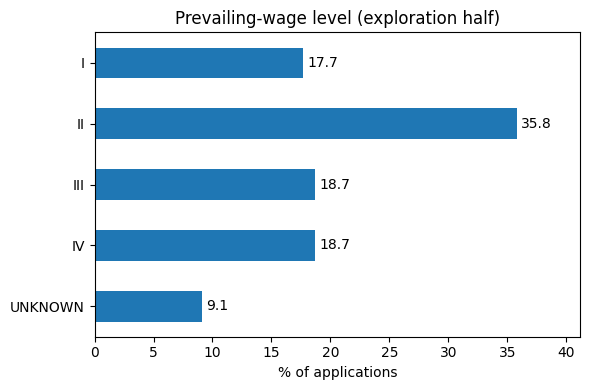

In [9]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def share(d, prefix, top=10):
    cols = [c for c in d.columns if c.startswith(prefix + "=")]
    s = d[cols].sum().sort_values(ascending=False) / len(d) * 100
    s.index = [c.split("=", 1)[1] for c in s.index]
    return s.head(top).round(1)

def bar(s, title, fname, xlabel="% of applications"):
    ax = s.plot.barh(figsize=(6, 4)); ax.invert_yaxis()
    ax.set_xlabel(xlabel); ax.set_title(title)
    ax.set_xlim(0, s.max() * 1.15)
    for i, v in enumerate(s): ax.text(v + s.max() * 0.01, i, f"{v:.1f}", va="center")
    plt.tight_layout(); plt.savefig(fname, dpi=200); plt.show(); plt.close()

bar(share(explore, "PW_WAGE_LEVEL").reindex(["I", "II", "III", "IV", "UNKNOWN"]),
    "Prevailing-wage level (exploration half)", "fig_wage_level.png")

CASE_STATUS
Certified                91.50
Certified - Withdrawn     6.19
Withdrawn                 1.72
Denied                    0.59
Name: proportion, dtype: float64
Not certified (withdrawn + denied): 2.31


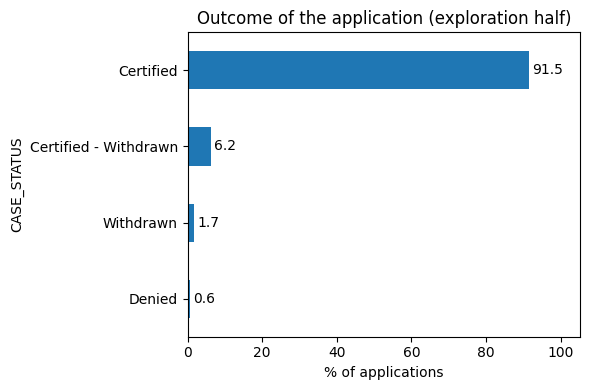

In [10]:
o = (explore["CASE_STATUS"].value_counts(normalize=True) * 100).round(2)
o = o.reindex(["Certified", "Certified - Withdrawn", "Withdrawn", "Denied"])
print(o)
print("Not certified (withdrawn + denied):", round(o["Withdrawn"] + o["Denied"], 2))
bar(o, "Outcome of the application (exploration half)", "fig_outcome.png")

## Explore occupation groups

Summarize the most common SOC major occupation groups in the exploration half. The chart answers which occupations account for the largest application shares. Occupation mix may also relate to outcome rates, so pooled comparisons should be interpreted with that context.

15    58.7
13    10.3
17    10.0
11     5.2
29     4.8
19     4.5
25     3.5
27     0.9
dtype: float64


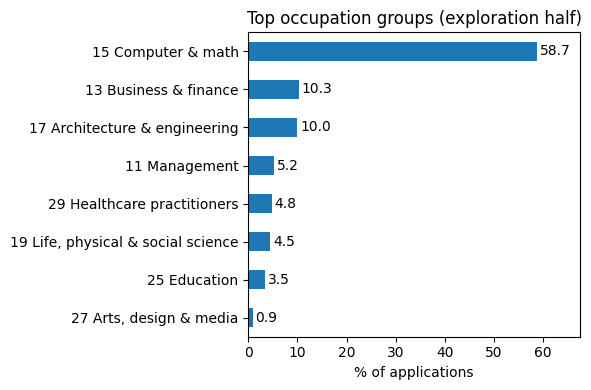

In [11]:
soc = {"11":"Management","13":"Business & finance","15":"Computer & math","17":"Architecture & engineering",
       "19":"Life, physical & social science","21":"Community & social service","23":"Legal","25":"Education",
       "27":"Arts, design & media","29":"Healthcare practitioners","31":"Healthcare support","41":"Sales",
       "43":"Office & admin","UNKNOWN":"Unknown"}
s = share(explore, "SOC_MAJOR", top=8)
print(s)
s.index = [f"{i} {soc.get(i, '')}".strip() for i in s.index]
bar(s, "Top occupation groups (exploration half)", "fig_occupation.png")

## Explore worksite states

Calculate and plot the ten most common worksite states in the exploration half. These are application shares by worksite location, not employer headquarters or state-specific approval effects.

CA    19.9
TX    14.4
NY     9.7
IL     4.9
NJ     4.5
NC     4.0
WA     3.9
GA     3.9
MA     3.6
FL     3.5
dtype: float64


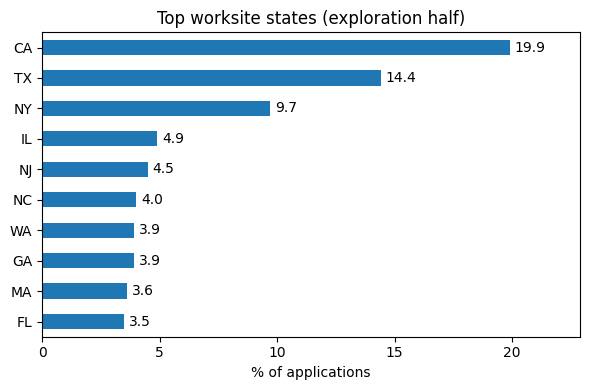

In [12]:
s = share(explore, "WORKSITE_STATE", top=10)
print(s)
bar(s, "Top worksite states (exploration half)", "fig_state.png")

## Explore agent use

Report the proportion of exploration-half applications indicating an agent represented the employer. This is a descriptive feature summary; the later comparison examines its association with the not-certified rate.

Share using an agent: 78.0 %


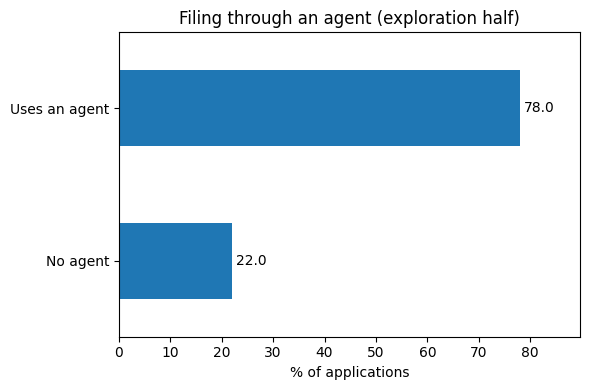

In [13]:
p = explore["AGENT_REPRESENTING_EMPLOYER"].mean() * 100
print("Share using an agent:", round(p, 1), "%")
bar(pd.Series({"Uses an agent": p, "No agent": 100 - p}).round(1),
    "Filing through an agent (exploration half)", "fig_agent.png")

## Compare exploratory rates across filing characteristics

For the exploration half, calculate not-certified counts and rates by prevailing-wage proximity, non-standard wage source, agent use, and whether the employer has more than one application (`repeat`). The prior-history comparison appears in the rates figure below. These are descriptive comparisons and should not be presented as confirmation tests.

In [14]:
e = explore.copy()
e["not_cert"] = e["CASE_STATUS"].isin(["Withdrawn", "Denied"]).astype(int)
e["emp_n"] = e.groupby("FEIN_ID")["FEIN_ID"].transform("size")
e["repeat"] = (e["emp_n"] >= 2).astype(int)
prem = e["HOURLY_OFFERED_WAGE"] / e["HOURLY_PREVAILING_WAGE"]
e["at_min"] = (prem <= 1.001).astype(int)           # exactly at the prevailing wage (within 0.1%)
print("min premium:", round(prem.min(), 4), "  below 1:", int((prem < 0.999).sum()))
for col in ["at_min", "HAS_NON_STANDARD_WAGE_SOURCE", "AGENT_REPRESENTING_EMPLOYER", "repeat"]:
    t = e.groupby(col)["not_cert"].agg(rows="size", not_certified="sum")
    t["rate_%"] = (t["not_certified"] / t["rows"] * 100).round(2)
    print("\n", col); print(t)

min premium: 1.0   below 1: 0

 at_min
          rows  not_certified  rate_%
at_min                               
0       138789           3277    2.36
1        75078           1653    2.20

 HAS_NON_STANDARD_WAGE_SOURCE
                                rows  not_certified  rate_%
HAS_NON_STANDARD_WAGE_SOURCE                               
0                             195558           4486    2.29
1                              18309            444    2.43

 AGENT_REPRESENTING_EMPLOYER
                               rows  not_certified  rate_%
AGENT_REPRESENTING_EMPLOYER                               
0                             47154           1492    3.16
1                            166713           3438    2.06

 repeat
          rows  not_certified  rate_%
repeat                               
0        13280            150    1.13
1       200587           4780    2.38


In [15]:
e["ym"] = e["RECEIVED_YEAR"] * 100 + e["RECEIVED_MONTH"]
first = (e.sample(frac=1, random_state=558)
          .sort_values("ym", kind="mergesort").drop_duplicates("FEIN_ID"))
t = first.groupby("repeat")["not_cert"].agg(rows="size", not_certified="sum")
t["rate_%"] = (t["not_certified"] / t["rows"] * 100).round(2); print(t)

         rows  not_certified  rate_%
repeat                              
0       13280            150    1.13
1       14379            888    6.18


In [16]:
prem = explore["HOURLY_OFFERED_WAGE"] / explore["HOURLY_PREVAILING_WAGE"]
print(prem.describe())
print("premium > 10:", int((prem > 10).sum()), "  exactly at prevailing (<=1.001):", int((prem <= 1.001).sum()))

count    213867.000000
mean          1.190233
std           0.465193
min           1.000000
25%           1.000000
50%           1.050727
75%           1.223005
max          27.165750
dtype: float64
premium > 10: 79   exactly at prevailing (<=1.001): 75078


## Plot the wage-premium distribution

Plot the log offered-to-prevailing-wage ratio for observations with a ratio no greater than 10. The log scale makes the distribution easier to inspect; the excluded high ratios are counted separately and should be disclosed.

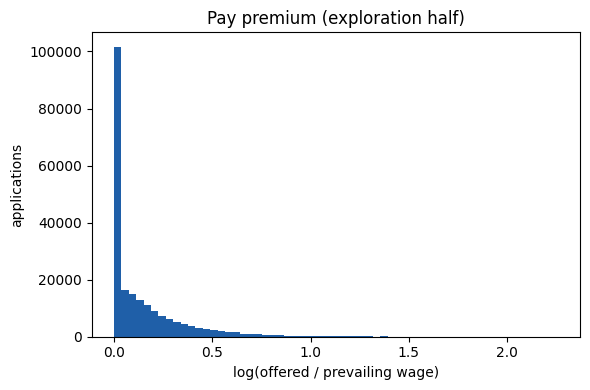

at the prevailing wage: 35.1 %  median ratio: 1.051


In [17]:
# 1. premium histogram
prem = explore["HOURLY_OFFERED_WAGE"] / explore["HOURLY_PREVAILING_WAGE"]
lp = np.log(prem[prem <= 10])
plt.figure(figsize=(6, 4)); plt.hist(lp, bins=60, color="#1f5fa8")
plt.xlabel("log(offered / prevailing wage)"); plt.ylabel("applications")
plt.title("Pay premium (exploration half)"); plt.tight_layout()
plt.savefig("fig_premium.png", dpi=200); plt.show()
print("at the prevailing wage:", round((lp <= 0.001).mean() * 100, 1), "%  median ratio:", round(prem.median(), 3))

In [18]:
# 2. before/after numbers
print("raw:", raw.shape, "-> prepared:", df.shape)
m = raw.replace("", np.nan).isna().mean() * 100
print("raw columns with any missing:", int((m > 0).sum()), " over 50% missing:", int((m > 50).sum()))
print("prepared missing cells:", int(df.isna().sum().sum()))
print("duplicate rows ignoring CASE_NUMBER (raw):", int(raw.drop(columns=["CASE_NUMBER"]).duplicated().sum()))
print("premium > 10 in exploration:", int((prem > 10).sum()))

raw: (437496, 98) -> prepared: (427599, 435)
raw columns with any missing: 53  over 50% missing: 24
prepared missing cells: 0
duplicate rows ignoring CASE_NUMBER (raw): 5998
premium > 10 in exploration: 79


## Plot exploratory not-certified rates by group

Display not-certified rates for the four planned features with simple binomial intervals. These intervals do not account for multiple applications from the same employer and are descriptive; the confirmation tests later provide the planned comparisons.

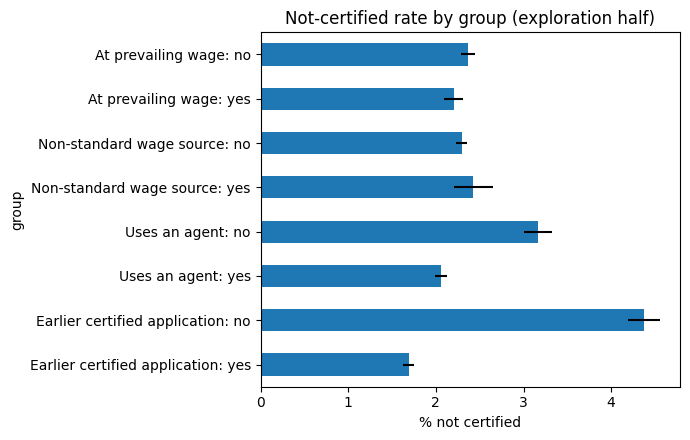

                                    rate    ci
group                                         
At prevailing wage: no              2.36  0.08
At prevailing wage: yes             2.20  0.10
Non-standard wage source: no        2.29  0.07
Non-standard wage source: yes       2.43  0.22
Uses an agent: no                   3.16  0.16
Uses an agent: yes                  2.06  0.07
Earlier certified application: no   4.38  0.18
Earlier certified application: yes  1.69  0.06


In [19]:
# 3. not-certified rate by group (naive 95% intervals)
rows = []
for col, lab in [("at_min", "At prevailing wage"), ("HAS_NON_STANDARD_WAGE_SOURCE", "Non-standard wage source"),
                 ("AGENT_REPRESENTING_EMPLOYER", "Uses an agent"), ("has_history", "Earlier certified application")]:
    for v in (0, 1):
        g = explore.loc[explore[col] == v, "not_cert"]; p = g.mean() * 100
        rows.append((f"{lab}: {'yes' if v else 'no'}", p, 1.96 * np.sqrt(p * (100 - p) / len(g))))
r = pd.DataFrame(rows, columns=["group", "rate", "ci"]).set_index("group")
ax = r["rate"].plot.barh(xerr=r["ci"], figsize=(7, 4.5)); ax.invert_yaxis()
ax.set_xlabel("% not certified"); ax.set_title("Not-certified rate by group (exploration half)")
plt.tight_layout(); plt.savefig("fig_rates.png", dpi=200); plt.show(); print(r.round(2))

## Explore outcome rates by occupation

Calculate not-certified rates for the six largest occupation groups in the exploration half. This shows variation across occupations and motivates caution when interpreting pooled results. The plot is not an occupation-adjusted test.

15 Computer & math                    1.83
13 Business & finance                 3.00
17 Architecture & engineering         2.48
11 Management                         3.42
29 Healthcare practitioners           2.74
19 Life, physical & social science    2.66
dtype: float64


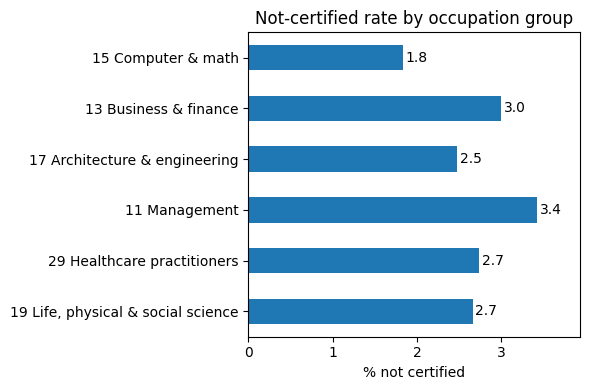

In [20]:
# 4. rate by occupation group
cols = [c for c in explore.columns if c.startswith("SOC_MAJOR=")]
top = explore[cols].sum().sort_values(ascending=False).head(6).index
r = pd.Series({c.split("=")[1]: explore.loc[explore[c] == 1, "not_cert"].mean() * 100 for c in top}).round(2)
r.index = [f"{i} {soc.get(i, '')}".strip() for i in r.index]
print(r); bar(r, "Not-certified rate by occupation group", "fig_rate_soc.png", xlabel="% not certified")

## Check overlap among planned features

Calculate pairwise correlations among the four binary filing characteristics in the exploration half. Correlation helps describe overlap but does not establish independence or remove confounding from the later group comparisons.

In [21]:
# 5. overlap between the four features
f = explore[["at_min", "HAS_NON_STANDARD_WAGE_SOURCE", "AGENT_REPRESENTING_EMPLOYER", "has_history"]].astype(float)
f.columns = ["at_min", "non_standard", "agent", "has_history"]
print(f.corr().round(2))

              at_min  non_standard  agent  has_history
at_min          1.00          0.06  -0.15         0.02
non_standard    0.06          1.00   0.06         0.08
agent          -0.15          0.06   1.00        -0.05
has_history     0.02          0.08  -0.05         1.00


## Measure employer concentration

Summarize how many employers appear, the median number of applications per employer, and the application share contributed by the largest employer and top one percent of employers. This informs the limitation that applications from the same employer are not independent.

In [22]:
# 6. employer concentration
n = explore.groupby("FEIN_ID").size().sort_values(ascending=False)
print("employers:", len(n), " median applications:", int(n.median()),
      " largest employer share:", round(n.iloc[0] / len(explore) * 100, 1), "%",
      " top 1% of employers share:", round(n.head(int(len(n) * 0.01)).sum() / len(explore) * 100, 1), "%")

employers: 27659  median applications: 2  largest employer share: 3.4 %  top 1% of employers share: 47.2 %


## Compute title similarity to an employer's earlier filings

In [23]:
title_cols = [c for c in df.columns if c.startswith("TITLE_")]
T = df[title_cols].to_numpy(np.float32)
recv = pd.to_datetime(raw.loc[df.index, "RECEIVED_DATE"], errors="coerce").to_numpy()
out = np.full(len(df), np.nan, dtype=np.float32)
for fein, idx in df.groupby("FEIN_ID").indices.items():
    if len(idx) < 2: continue
    idx = idx[np.argsort(recv[idx], kind="mergesort")]
    d, X = recv[idx], T[idx]
    pos = np.searchsorted(d, d, side="left")          # number of strictly earlier applications
    C = np.vstack([np.zeros((1, X.shape[1]), np.float32), np.cumsum(X, axis=0)])
    dot = (X * C[pos]).sum(1)
    out[idx] = np.where(pos > 0, dot / np.maximum(pos, 1), np.nan)
df["title_sim_prior"] = out
print("share of titles with no vocabulary terms (zero vector):", round((T.sum(1) == 0).mean() * 100, 1), "%")

e = df[df["half"] == "exploration"]                    # look at the exploration half only
print(e["title_sim_prior"].describe())
q = pd.qcut(e["title_sim_prior"], 4, duplicates="drop")
print(e.groupby(q, observed=True)["not_cert"].agg(rows="size", rate=lambda s: round(s.mean() * 100, 2)))

share of titles with no vocabulary terms (zero vector): 4.7 %
count    182507.000000
mean          0.284703
std           0.264469
min           0.000000
25%           0.075330
50%           0.209705
75%           0.424529
max           1.000000
Name: title_sim_prior, dtype: float64
                   rows  rate
title_sim_prior              
(-0.001, 0.0753]  45627  2.03
(0.0753, 0.21]    45628  1.67
(0.21, 0.425]     45626  1.55
(0.425, 1.0]      45626  1.67


## Explore rates across title-similarity bands

Group exploration-half applications with an earlier title into similarity bands and summarize their not-certified rates. The plot is exploratory and should not be interpreted as evidence that title similarity changes an outcome.

                      rows  rate    ci
band                                  
no overlap\n(0)      22769  2.32  0.20
low\n(0-0.25)        78967  1.67  0.09
mid\n(0.25-0.5)      44817  1.62  0.12
high\n(0.5-0.75)     22451  1.14  0.14
very high\n(0.75-1)   6315  1.33  0.28
identical\n(1)        7188  3.31  0.41


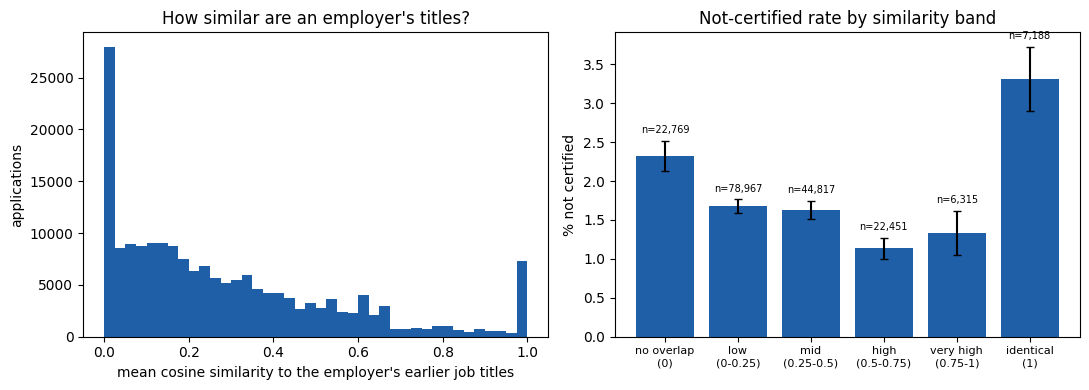

In [24]:
e = df[(df["half"] == "exploration") & df["title_sim_prior"].notna()].copy()

bands = [-0.001, 0.001, 0.25, 0.5, 0.75, 0.999, 1.001]
labels = ["no overlap\n(0)", "low\n(0-0.25)", "mid\n(0.25-0.5)", "high\n(0.5-0.75)", "very high\n(0.75-1)", "identical\n(1)"]
e["band"] = pd.cut(e["title_sim_prior"], bands, labels=labels)

g = e.groupby("band", observed=True)["not_cert"].agg(rows="size", rate=lambda s: s.mean() * 100)
g["ci"] = 1.96 * np.sqrt(g["rate"] * (100 - g["rate"]) / g["rows"])
print(g.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(e["title_sim_prior"], bins=40, color="#1f5fa8")
ax[0].set_xlabel("mean cosine similarity to the employer's earlier job titles")
ax[0].set_ylabel("applications"); ax[0].set_title("How similar are an employer's titles?")

ax[1].bar(range(len(g)), g["rate"], yerr=g["ci"], color="#1f5fa8", capsize=3)
ax[1].set_xticks(range(len(g))); ax[1].set_xticklabels(g.index, fontsize=8)
for i, (r, n) in enumerate(zip(g["rate"], g["rows"])):
    ax[1].text(i, r + g["ci"].iloc[i] + 0.1, f"n={n:,}", ha="center", fontsize=7)
ax[1].set_ylabel("% not certified"); ax[1].set_title("Not-certified rate by similarity band")
plt.tight_layout(); plt.savefig("fig_title_sim.png", dpi=200); plt.show()

## Check who drives the highest similarity band

In [25]:
titles = raw.loc[df.index, "JOB_TITLE"].astype(str).str.strip()
names = raw.loc[df.index, "EMPLOYER_NAME"].astype(str).str.strip()
e = df[(df["half"] == "exploration") & df["title_sim_prior"].notna()].copy()
e["title"], e["employer"] = titles, names
e["band"] = pd.cut(e["title_sim_prior"], [-0.001, 0.001, 0.25, 0.5, 0.75, 0.999, 1.001],
                   labels=["no overlap", "low", "mid", "high", "very high", "identical"])

# 1. who drives the identical band
ident = e[e["band"] == "identical"]
vc = ident["employer"].value_counts()
print(vc.head(10))
print("top 10 employers' share of the identical band:", round(vc.head(10).sum() / len(ident) * 100, 1), "%")
print("employers in the identical band:", len(vc))

# how many 'no overlap' titles are simply outside the vocabulary (zero vector)
posn = df.index.get_indexer(e.index)
zero = (T[posn].sum(1) == 0)
print("no-overlap rows whose own title has no vocabulary terms:",
      round(zero[(e["band"] == "no overlap").to_numpy()].mean() * 100, 1), "%")

employer
Cosmic Healthcare, LLC                       78
DECOFRUT INC                                 45
Comtrix Solutions, Inc.                      41
Spear Physical Therapy, PLLC                 37
Portsmouth Public Schools                    33
West Contra Costa Unified School District    30
Fujitsu North America, Inc.                  29
UPSTATE CEREBRAL PALSY, INC.                 29
NEON IT LLC                                  26
ENLIGHTENED SOLUTIONS LLC                    26
Name: count, dtype: int64
top 10 employers' share of the identical band: 5.2 %
employers in the identical band: 4345
no-overlap rows whose own title has no vocabulary terms: 33.8 %


## Show example titles from each similarity band

In [26]:
# 2. examples: an application's title vs its closest earlier title from the same employer
grp = df.groupby("FEIN_ID").indices
fein = df["FEIN_ID"].to_numpy()
def closest(p):
    idx = grp[fein[p]]; idx = idx[recv[idx] < recv[p]]
    s = T[idx] @ T[p]; j = s.argmax()
    return titles.iloc[idx[j]], round(float(s[j]), 2)

rows = []
for b, g in e.groupby("band", observed=True):
    for ix in g.sample(5, random_state=558).index:
        p = df.index.get_loc(ix)
        t0, s0 = closest(p)
        rows.append((b, titles.loc[ix][:45], t0[:45], s0, round(float(df.at[ix, "title_sim_prior"]), 2)))
out = pd.DataFrame(rows, columns=["band", "this application", "closest earlier title", "closest sim", "mean sim"])
pd.set_option("display.max_colwidth", 50, "display.width", 200)
print(out.to_string(index=False))

      band                              this application                         closest earlier title  closest sim  mean sim
no overlap                                      Lecturer              Data Analytics Science Analyst 3         0.00      0.00
no overlap                        Cloud engineer /AWS AI                            Software Developer         0.00      0.00
no overlap                                     Clinician    Residential Counselor - Professional Level         0.00      0.00
no overlap                                  DATA ANALYST         CSV Consultant (Compliance & Quality)         0.00      0.00
no overlap                            Programmer Analyst                            Software Architect         0.00      0.00
       low                                       Analyst                                       Analyst         1.00      0.19
       low                              Research Analyst                                  Data Analyst         0.19   

In [27]:
tn = titles.str.lower().str.replace(r"[^a-z0-9 ]", " ", regex=True).str.split().str.join(" ").to_numpy()
d = pd.DataFrame({"f": fein, "t": tn, "r": recv})
first = d.groupby(["f", "t"])["r"].transform("min")
df["title_repeat"] = (d["r"] > first).astype(int).to_numpy()    # same employer filed this title earlier

e = df[(df["half"] == "exploration") & df["title_sim_prior"].notna()]   # applications with an earlier filing
t = e.groupby("title_repeat")["not_cert"].agg(rows="size", not_certified="sum")
t["rate_%"] = (t["not_certified"] / t["rows"] * 100).round(2); print(t)

                rows  not_certified  rate_%
title_repeat                               
0              76665           1498    1.95
1             105842           1658    1.57


## Explore industry-sector shares and rates

Summarize the largest NAICS industry sectors by application share and not-certified rate. Sector rates vary in sample size and employer concentration, so use the counts and intervals as descriptive context rather than as confirmatory findings.

                                      rows  share  rate    ci
sector                                                       
54 Professional, scientific & tech  105940  49.54  2.21  0.09
31 Manufacturing                     23115  10.81  2.06  0.18
52 Finance & insurance               19998   9.35  1.82  0.19
51 Information                       17116   8.00  1.43  0.18
61 Educational services              16601   7.76  2.80  0.25
62 Health care                        9186   4.30  3.51  0.38
56 Admin & support                    4780   2.24  2.05  0.40
44 Retail                             4057   1.90  2.17  0.45


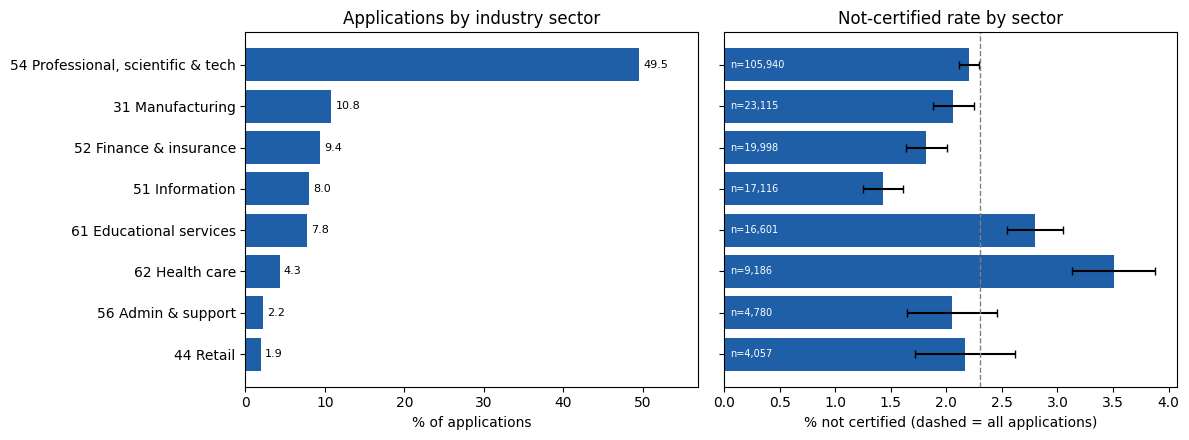

In [28]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
naics = {"54":"Professional, scientific & tech","51":"Information","52":"Finance & insurance","61":"Educational services",
         "62":"Health care","31":"Manufacturing","32":"Manufacturing","33":"Manufacturing","42":"Wholesale",
         "44":"Retail","45":"Retail","56":"Admin & support","72":"Accommodation & food","81":"Other services",
         "53":"Real estate","23":"Construction","48":"Transportation","49":"Transportation","55":"Management of companies",
         "92":"Public administration","71":"Arts & recreation","11":"Agriculture","21":"Mining","22":"Utilities"}
cols = [c for c in explore.columns if c.startswith("NAICS_SECTOR=")]
top = explore[cols].sum().sort_values(ascending=False).head(8).index

rows = []
for c in top:
    m = explore[c] == 1
    n = int(m.sum()); p = explore.loc[m, "not_cert"].mean() * 100
    code = c.split("=")[1]
    rows.append((f"{code} {naics.get(code, '')}".strip(), n, n / len(explore) * 100, p, 1.96 * np.sqrt(p * (100 - p) / n)))
r = pd.DataFrame(rows, columns=["sector", "rows", "share", "rate", "ci"]).set_index("sector")
print(r.round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
ax[0].barh(r.index, r["share"], color="#1f5fa8"); ax[0].invert_yaxis()
ax[0].set_xlabel("% of applications"); ax[0].set_title("Applications by industry sector")
for i, v in enumerate(r["share"]): ax[0].text(v + 0.5, i, f"{v:.1f}", va="center", fontsize=8)
ax[0].set_xlim(0, r["share"].max() * 1.15)

ax[1].barh(r.index, r["rate"], xerr=r["ci"], color="#1f5fa8", capsize=3)
ax[1].axvline(explore["not_cert"].mean() * 100, color="gray", ls="--", lw=1)
ax[1].set_xlabel("% not certified (dashed = all applications)"); ax[1].set_title("Not-certified rate by sector")
for i, n in enumerate(r["rows"]): ax[1].text(0.05, i, f"n={n:,}", va="center", fontsize=7, color="white")
plt.tight_layout(); plt.savefig("fig_naics.png", dpi=200); plt.show()

In [29]:
for c in ["NAICS_SECTOR=44", "NAICS_SECTOR=51", "NAICS_SECTOR=62"]:
    s = explore[explore[c] == 1]; v = s["FEIN_ID"].value_counts()
    print(c, "employers:", len(v), " top employer share:", round(v.iloc[0] / len(s) * 100, 1), "%  top 5:", round(v.head(5).sum() / len(s) * 100, 1), "%")

NAICS_SECTOR=44 employers: 815  top employer share: 16.7 %  top 5: 37.9 %
NAICS_SECTOR=51 employers: 1753  top employer share: 28.6 %  top 5: 46.1 %
NAICS_SECTOR=62 employers: 2441  top employer share: 1.6 %  top 5: 6.5 %


In [30]:
s = explore[explore["NAICS_SECTOR=44"] == 1]
top = s["FEIN_ID"].value_counts().index[0]
rest = s[s["FEIN_ID"] != top]
print("top employer:", round(s.loc[s["FEIN_ID"] == top, "not_cert"].mean() * 100, 2), "%  n =", int((s["FEIN_ID"] == top).sum()))
print("rest of retail:", round(rest["not_cert"].mean() * 100, 2), "%  n =", len(rest))

top employer: 0.44 %  n = 679
rest of retail: 2.52 %  n = 3378


## Check missing wage levels and non-standard sources

Cross-tabulate the unknown prevailing-wage-level flag against the non-standard wage-source flag. This describes how the two features overlap and helps interpret why the T4 comparison is not independent of wage-level information.

In [31]:
print(pd.crosstab(explore["PW_WAGE_LEVEL=UNKNOWN"], explore["HAS_NON_STANDARD_WAGE_SOURCE"]))

HAS_NON_STANDARD_WAGE_SOURCE       0      1
PW_WAGE_LEVEL=UNKNOWN                      
0                             194341      0
1                               1217  18309


## Re-plot the sector figure without retail's largest employer

Remove retail's largest employer, recompute retail's row count, share and rate, and redraw the sector figure so one employer does not dominate the retail bar.

In [32]:
s = explore[explore["NAICS_SECTOR=44"] == 1]
top = s["FEIN_ID"].value_counts().index[0]
rest = s[s["FEIN_ID"] != top]; p = rest["not_cert"].mean() * 100
r = r.rename(index={"44 Retail (excl. 1 employer)": "44 Retail"})   # undo an earlier run so re-running is safe
r = r[~r.index.duplicated(keep="first")]
r.loc["44 Retail", ["rows", "share", "rate", "ci"]] = [len(rest), len(rest) / len(explore) * 100, p, 1.96 * np.sqrt(p * (100 - p) / len(rest))]
r = r.rename(index={"44 Retail": "44 Retail (excl. 1 employer)"})
print(r.round(2))

                                      rows  share  rate    ci
sector                                                       
54 Professional, scientific & tech  105940  49.54  2.21  0.09
31 Manufacturing                     23115  10.81  2.06  0.18
52 Finance & insurance               19998   9.35  1.82  0.19
51 Information                       17116   8.00  1.43  0.18
61 Educational services              16601   7.76  2.80  0.25
62 Health care                        9186   4.30  3.51  0.38
56 Admin & support                    4780   2.24  2.05  0.40
44 Retail (excl. 1 employer)          3378   1.58  2.52  0.53


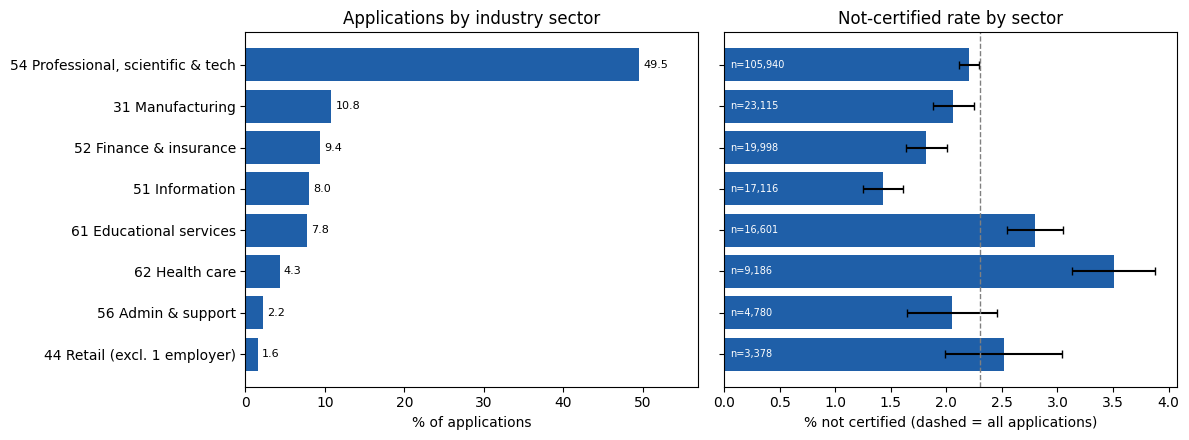

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
ax[0].barh(r.index, r["share"], color="#1f5fa8"); ax[0].invert_yaxis()
ax[0].set_xlabel("% of applications"); ax[0].set_title("Applications by industry sector")
for i, v in enumerate(r["share"]): ax[0].text(v + 0.5, i, f"{v:.1f}", va="center", fontsize=8)
ax[0].set_xlim(0, r["share"].max() * 1.15)
ax[1].barh(r.index, r["rate"], xerr=r["ci"], color="#1f5fa8", capsize=3)
ax[1].axvline(explore["not_cert"].mean() * 100, color="gray", ls="--", lw=1)
ax[1].set_xlabel("% not certified (dashed = all applications)"); ax[1].set_title("Not-certified rate by sector")
for i, n in enumerate(r["rows"]): ax[1].text(0.05, i, f"n={int(n):,}", va="center", fontsize=7, color="white")
plt.tight_layout(); plt.savefig("fig_naics.png", dpi=200); plt.show()

In [34]:
import zipfile
from pathlib import Path

captions = {
 "fig_outcome.png": "91.5% of applications are certified and 6.2% are certified then withdrawn. Only 2.3% end withdrawn (1.7%) or denied (0.6%), so always guessing 'certified' would be right 97.7% of the time.",
 "fig_rates.png": "Applications with no earlier certified application are not certified 4.38% of the time, against 1.69% with one. Applications filed without an agent are not certified 3.16% of the time, against 2.06% with one; the two wage comparisons differ by under 0.2 points. Intervals ignore employer clustering.",
 "fig_naics.png": "Professional, scientific and technical services file 49.5% of applications. Not-certified rates run from 1.4% (information) to 3.5% (health care) around the 2.3% average. Retail is shown without its largest employer (16.7% of retail applications, 0.44% not certified); the rest of retail is 2.52%. Intervals ignore employer clustering.",
 "fig_rate_soc.png": "Not-certified rates run from 1.8% (computer and math) to 3.4% (management), so occupation may confound the pooled tests; T1 is re-checked within computer and math occupations in Section 5.",
 "fig_premium.png": "About a third of applications (35.1%) offer exactly the prevailing wage; the median offer is 5.1% above it, and none is below. The 79 applications with a ratio above 10 are not plotted.",
 "fig_agent.png": "78.0% of applications are filed through an agent.",
 "fig_wage_level.png": "Level II is the most common prevailing-wage level (35.8%); levels I, III and IV each hold 18-19%. 9.1% have no level, and 93.8% of those use a non-standard wage source.",
 "fig_occupation.png": "Computer and mathematical occupations make up 58.7% of applications. Business & finance and architecture & engineering add about 10% each, so the top three cover about 79%.",
 "fig_state.png": "Four states (CA, TX, NY, IL) hold about 49% of worksites, and the top ten hold about 72%.",
 "fig_title_sim.png": "Mean similarity to an employer's earlier titles measures how varied its job titles are. Titles outside the 150-term vocabulary score 0, so the spikes at 0 and 1 partly reflect that limit; an exact-match check gives 1.57% not certified for repeated titles vs 1.95% for new ones.",
}

def find(name):
    for d in (Path("."), Path(OUTPUT_DIR)):
        if (d / name).exists():
            return d / name

out = Path(OUTPUT_DIR); out.mkdir(exist_ok=True)
zpath = out / "figures_and_captions.zip"
notes, tex, missing = [], [], []
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
    for name, cap in captions.items():
        p = find(name)
        if p is None:
            missing.append(name); continue
        z.write(p, name)
        notes.append(f"{name}\n  {cap}\n")
        esc = cap.replace("&", "\\&").replace("%", "\\%")
        tex.append("\\begin{figure}[t]\n  \\centering\n  \\includegraphics[width=\\linewidth]{%s}\n  \\caption{%s}\n\\end{figure}\n" % (name, esc))
    z.writestr("captions.txt", "\n".join(notes))
    z.writestr("captions.tex", "\n".join(tex))
print("zipped:", len(captions) - len(missing), "figures   missing:", missing)
print("download from the Output panel:", zpath)

zipped: 10 figures   missing: []
download from the Output panel: /kaggle/working/figures_and_captions.zip


## Optional: package heatmaps

This optional utility packages the heatmap images for inspection or download. It is not part of the primary analysis and can be skipped when producing the report’s final figures.

heatmap_numeric_before (1852, 1702)


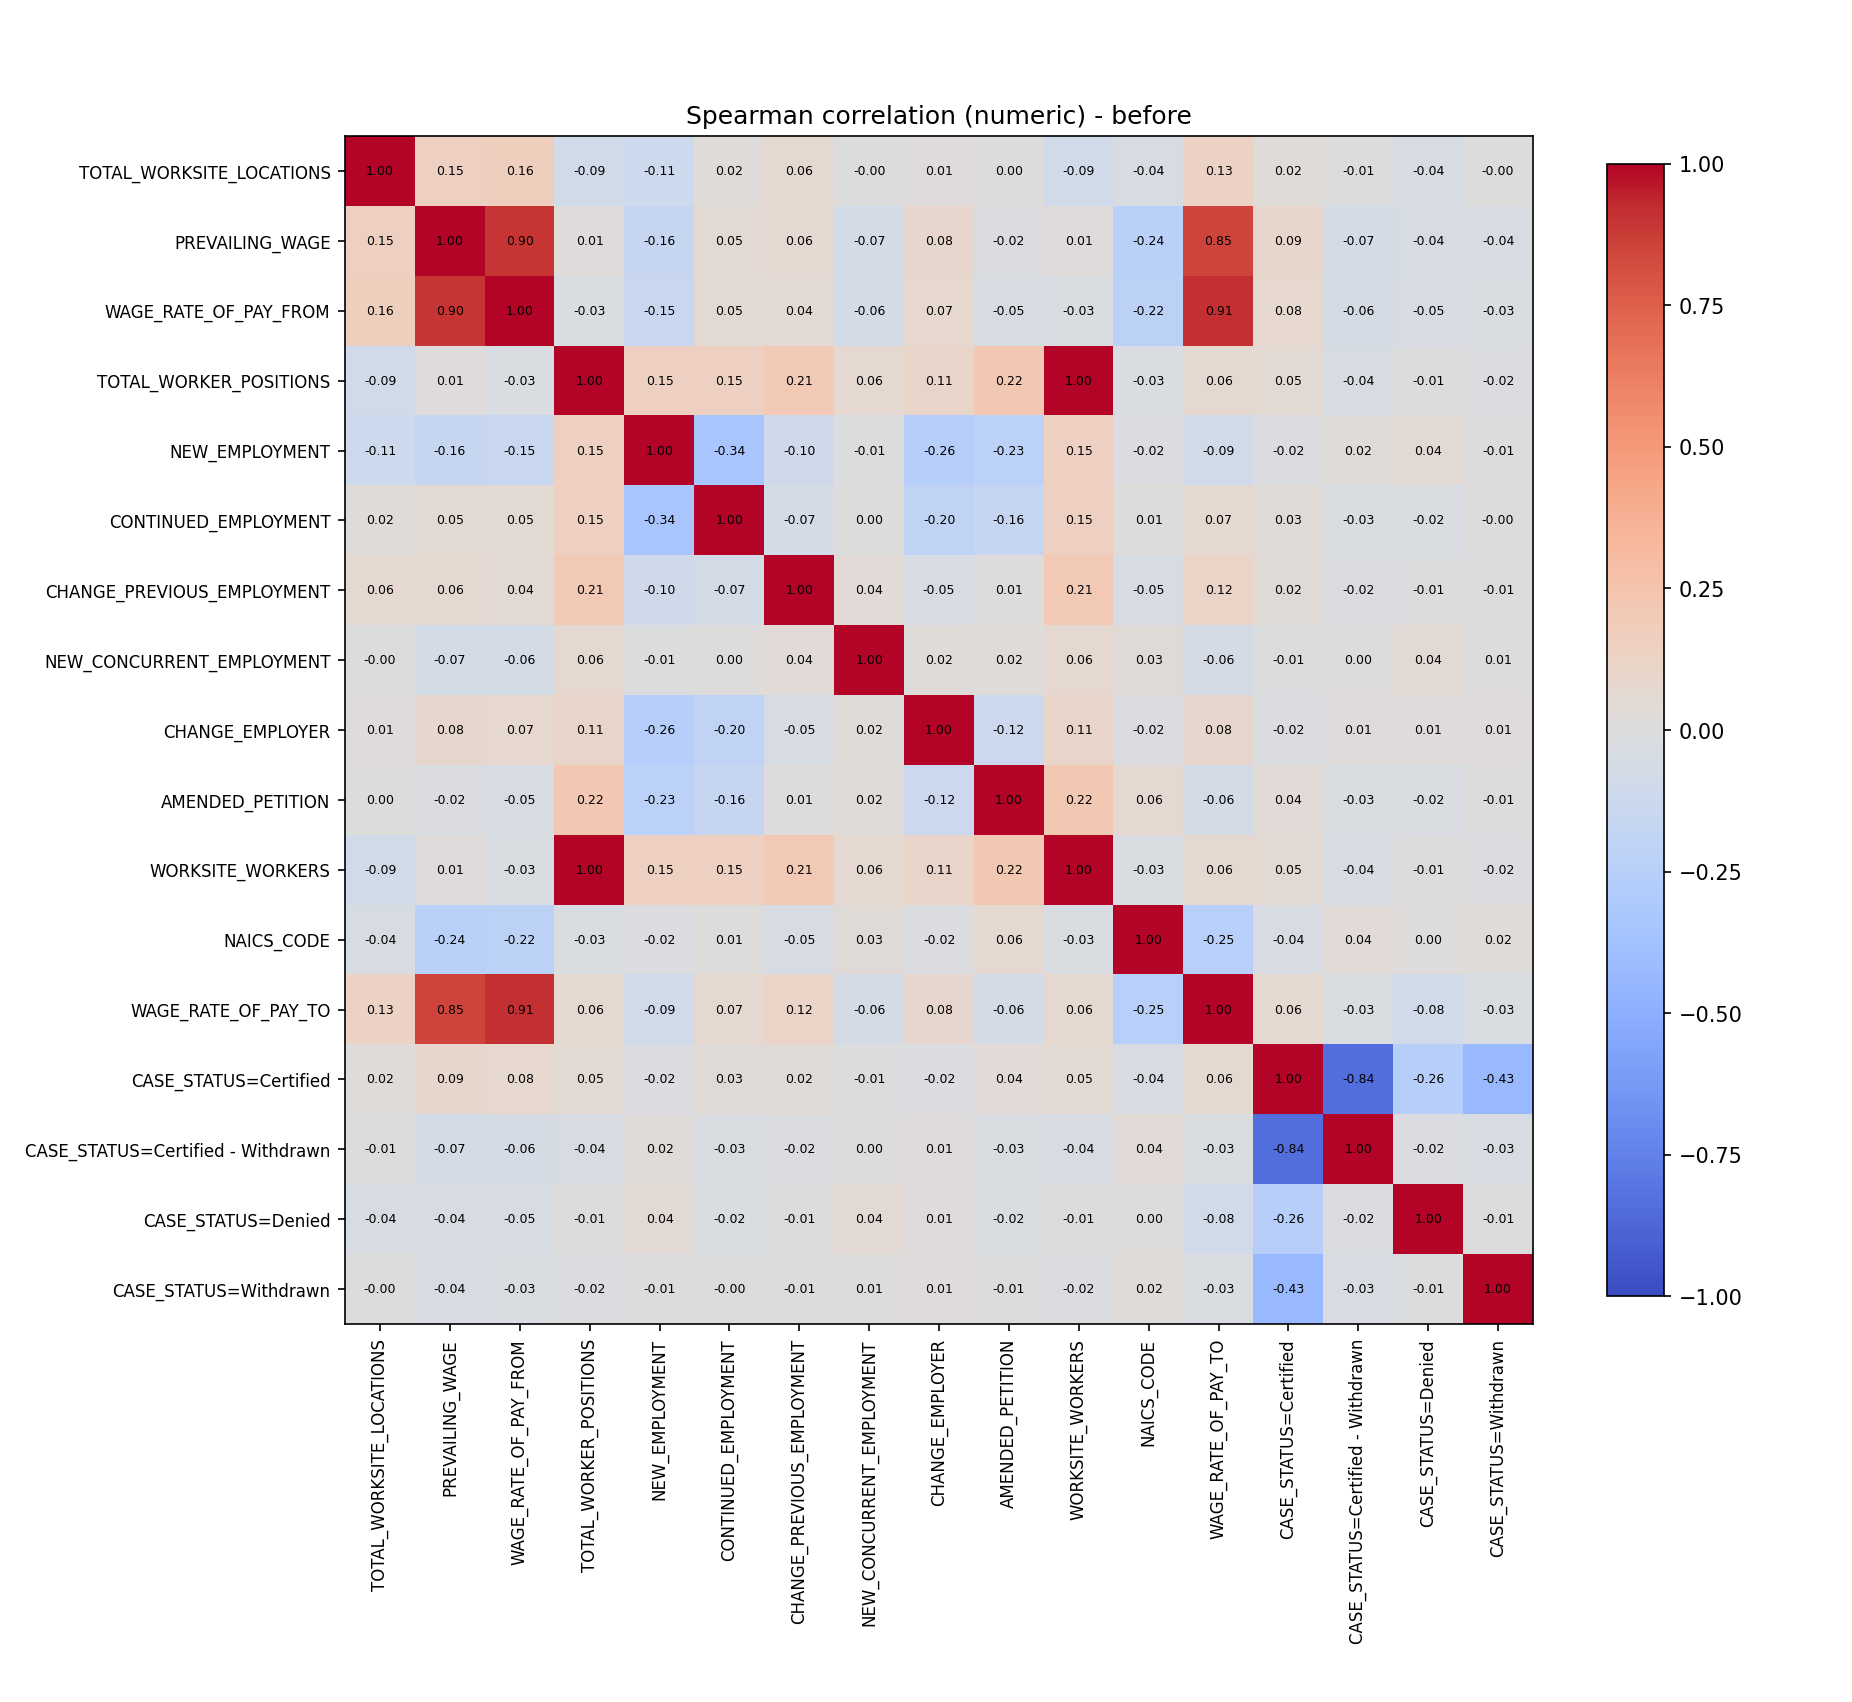

heatmap_numeric_after (3585, 3435)


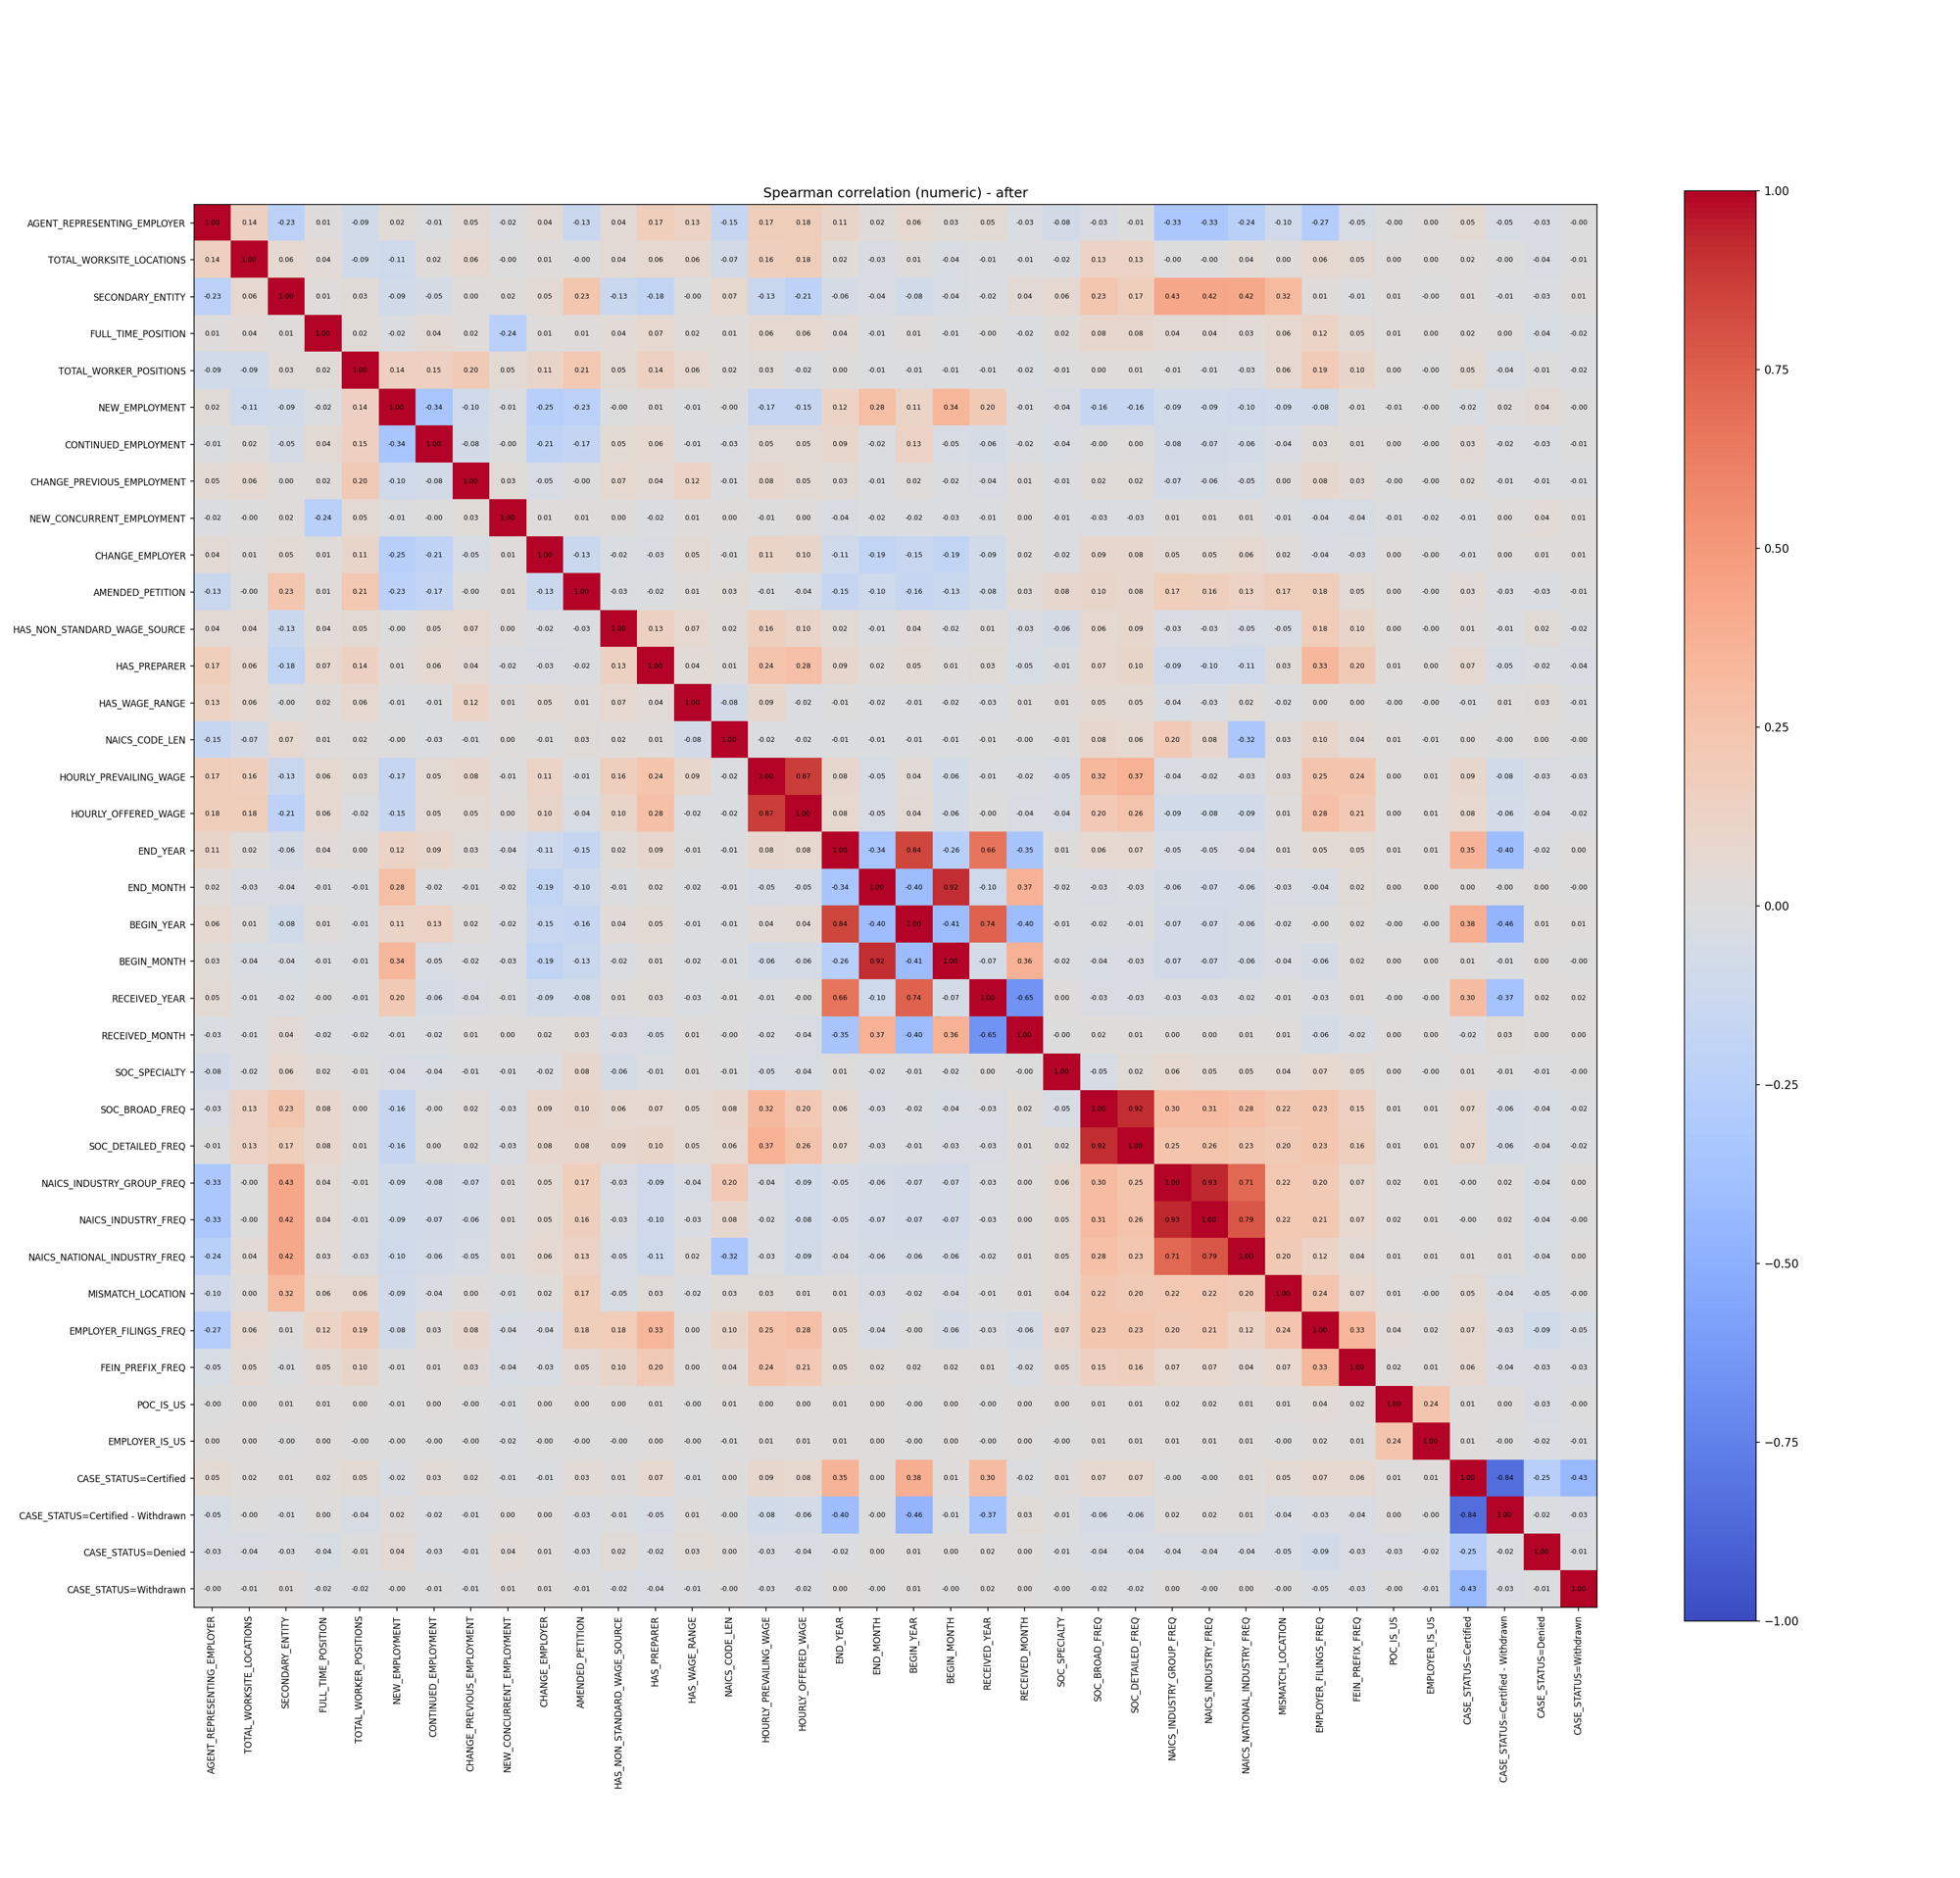

heatmap_categorical_before (2017, 1867)


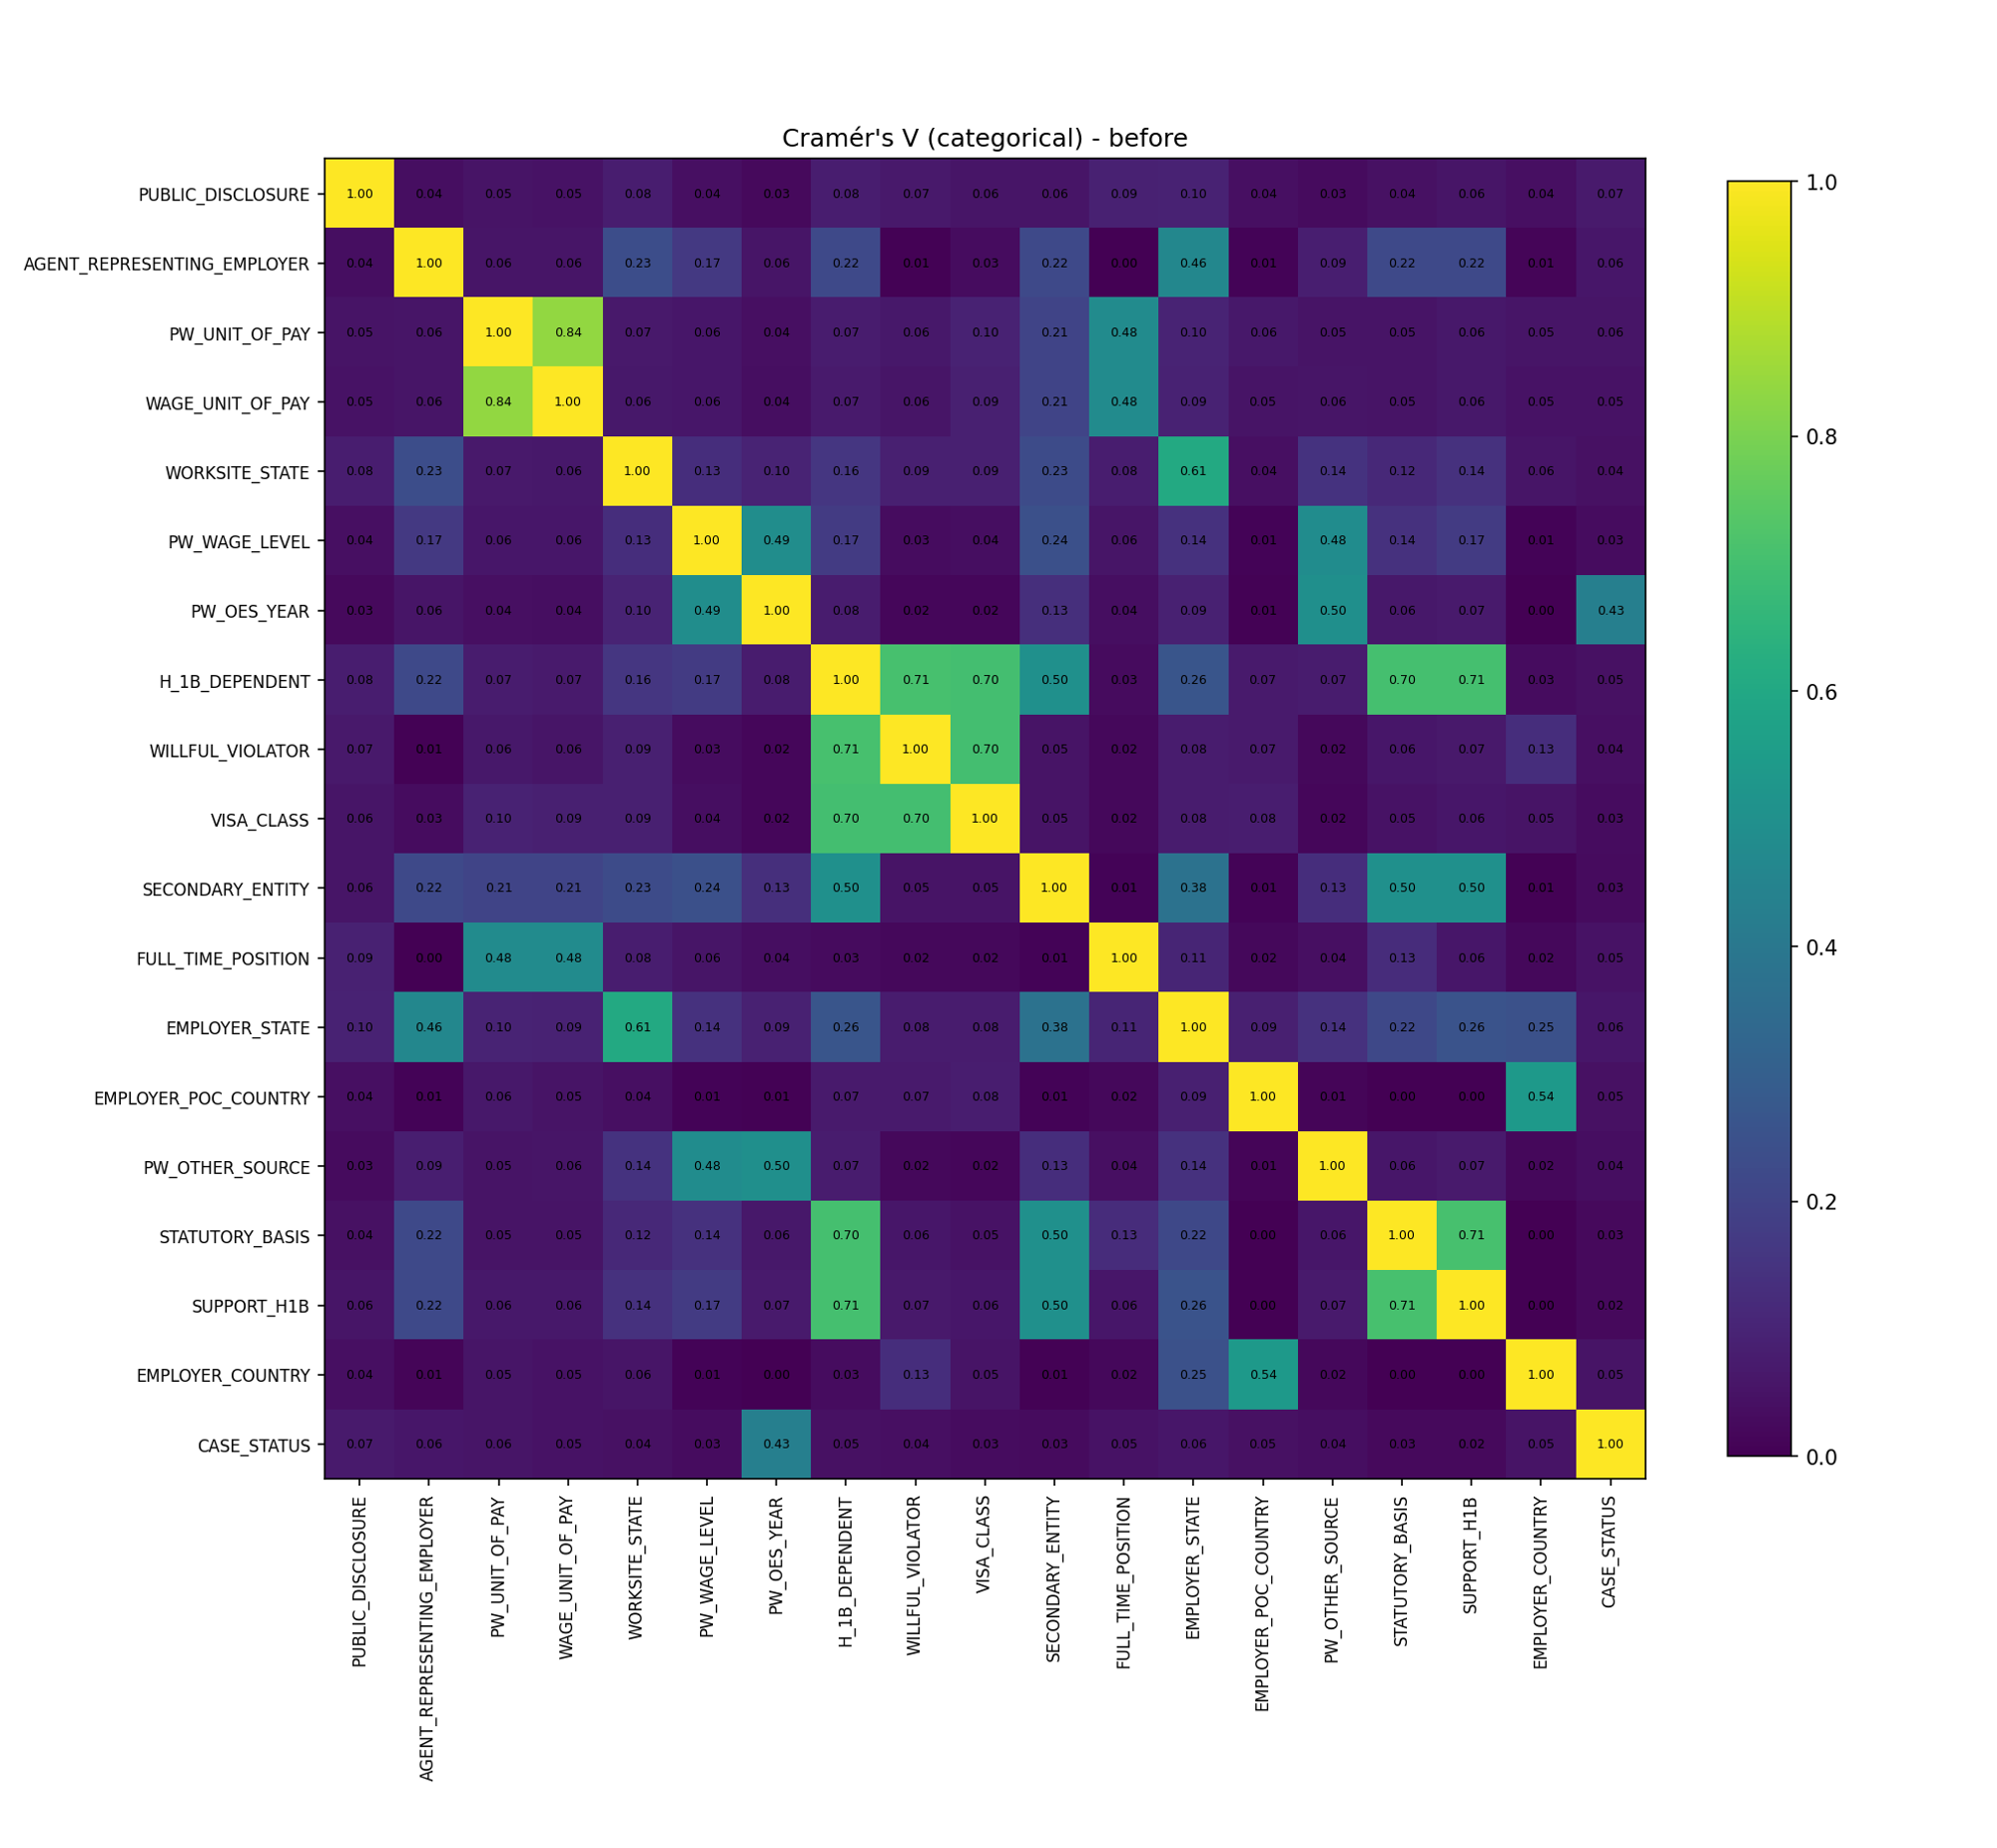

heatmap_categorical_after.png: not created (no usable columns of that type)
zip ready: /kaggle/working/heatmaps.zip


In [35]:
#optional-heatmaps:supposed to be done before EDA
from pathlib import Path
import zipfile
from PIL import Image as PILImage
from IPython.display import Image, display

PILImage.MAX_IMAGE_PIXELS = None          # allow the huge numeric_after PNG
out = Path(OUTPUT_DIR)
names = ["heatmap_numeric_before", "heatmap_numeric_after",
         "heatmap_categorical_before", "heatmap_categorical_after"]

preview_dir = out / "previews"
preview_dir.mkdir(exist_ok=True)

found = []
for n in names:
    p = out / f"{n}.png"
    if not p.exists():
        print(f"{n}.png: not created (no usable columns of that type)")
        continue
    with PILImage.open(p) as im:
        print(n, im.size)
        im.thumbnail((2000, 2000))        # shrink for display only
        q = preview_dir / f"{n}_preview.png"
        im.save(q)
    display(Image(str(q)))
    found.append(p)

# zip the full-size PNGs + rankings + summary
with zipfile.ZipFile(out / "heatmaps.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for p in found:
        z.write(p, p.name)
    for p in sorted(out.glob("corr_with_denied_*.csv")):
        z.write(p, p.name)
    if (out / "summary.csv").exists():
        z.write(out / "summary.csv", "summary.csv")
print("zip ready:", out / "heatmaps.zip")

## Confirmation test T1 for P1: earlier certified application

Compare the confirmation-half not-certified rate for employers with an earlier certified application against the rate for employers without one. The planned hypotheses are H0: p1 = p0 and H1: p1 ≠ p0, using a two-sided pooled two-proportion z-test at α = 0.05. Report the rate difference and unpooled 95% confidence interval, and judge practical size against the pre-set 1 percentage-point threshold. Interpret this as association, not cause.

In [36]:
# T1 (P1): earlier certified application
import numpy as np, pandas as pd
from scipy.stats import norm, chi2_contingency

d = confirm
g1 = d[d["has_history"]==1]["not_cert"]; g2 = d[d["has_history"]==0]["not_cert"]
n1, n2 = len(g1), len(g2); x1, x2 = g1.sum(), g2.sum()
p1, p2 = x1/n1, x2/n2
print(f"with history: n={n1}, count={x1}, p1={p1*100:.2f}%")
print(f"no history:   n={n2}, count={x2}, p2={p2*100:.2f}%")

# z-test for two proportions (pooled), Lecture 7
p = (x1+x2)/(n1+n2)
z = (p1-p2)/np.sqrt(p*(1-p)*(1/n1+1/n2))
pval = 2*norm.sf(abs(z))          # 1 - cdf(z) underflows to 0 for large z
print(f"pooled p={p:.4f}, z={z:.2f}, p-value={pval:.3g}, critical +/-1.96")

# chi-square test for independence, Lecture 8 (z^2 should equal chi2)
chi2, pc, dof, exp = chi2_contingency(pd.crosstab(d["has_history"], d["not_cert"]), correction=False)
print(f"chi2={chi2:.2f}, d.f.={dof}, p={pc:.3g}, z^2={z**2:.2f}")
print("smallest expected count:", exp.min().round(1))

# 95% CI for p1 - p2, Lecture 5 form
se = np.sqrt(p1*(1-p1)/n1 + p2*(1-p2)/n2)
print(f"difference = {(p1-p2)*100:.2f} points, 95% CI ({(p1-p2-1.96*se)*100:.2f}, {(p1-p2+1.96*se)*100:.2f})")
p_T1 = pval

with history: n=164953, count=2521, p1=1.53%
no history:   n=48779, count=2122, p2=4.35%
pooled p=0.0217, z=-37.56, p-value=1.01e-308, critical +/-1.96
chi2=1410.66, d.f.=1, p=1.01e-308, z^2=1410.66
smallest expected count: 1059.6
difference = -2.82 points, 95% CI (-3.01, -2.63)


## Confirmation test T2 for P1: agent representation

Compare confirmation-half not-certified rates for applications with and without an agent. Use the same two-sided pooled two-proportion z-test, α = 0.05, and pre-set 1 percentage-point meaningful-difference threshold. Report the difference and unpooled 95% confidence interval; the comparison is pooled across occupations and may overlap with employer experience and size.

In [37]:
# T2 (P1): filed through an agent
import numpy as np, pandas as pd
from scipy.stats import norm, chi2_contingency

d = confirm.dropna(subset=["AGENT_REPRESENTING_EMPLOYER"]).copy()
d["agent"] = d["AGENT_REPRESENTING_EMPLOYER"].astype(int)
print("rows dropped for missing agent flag:", len(confirm)-len(d))
g1 = d[d["agent"]==1]["not_cert"]; g2 = d[d["agent"]==0]["not_cert"]
n1, n2 = len(g1), len(g2); x1, x2 = g1.sum(), g2.sum()
p1, p2 = x1/n1, x2/n2
print(f"agent:    n={n1}, count={x1}, p1={p1*100:.2f}%")
print(f"no agent: n={n2}, count={x2}, p2={p2*100:.2f}%")

p = (x1+x2)/(n1+n2)
z = (p1-p2)/np.sqrt(p*(1-p)*(1/n1+1/n2))
pval = 2*norm.sf(abs(z))
print(f"pooled p={p:.4f}, z={z:.2f}, p-value={pval:.3g}, critical +/-1.96")

chi2, pc, dof, exp = chi2_contingency(pd.crosstab(d["agent"], d["not_cert"]), correction=False)
print(f"chi2={chi2:.2f}, d.f.={dof}, p={pc:.3g}, z^2={z**2:.2f}, smallest expected={exp.min():.1f}")

se = np.sqrt(p1*(1-p1)/n1 + p2*(1-p2)/n2)
print(f"difference = {(p1-p2)*100:.2f} points, 95% CI ({(p1-p2-1.96*se)*100:.2f}, {(p1-p2+1.96*se)*100:.2f})")
p_T2 = pval

rows dropped for missing agent flag: 0
agent:    n=154079, count=3222, p1=2.09%
no agent: n=59653, count=1421, p2=2.38%
pooled p=0.0217, z=-4.14, p-value=3.49e-05, critical +/-1.96
chi2=17.13, d.f.=1, p=3.49e-05, z^2=17.13, smallest expected=1295.9
difference = -0.29 points, 95% CI (-0.43, -0.15)


## Confirmation test T1 for P2: at the prevailing wage

Define the two groups by the `at_min` flag, run the pooled two-proportion z-test, and also compare the result with a chi-square test of independence. The second run excludes extreme offered-to-prevailing wage ratios above 10 as a sensitivity check. State the group definition, direction of the difference, confidence interval, and whether its size reaches 1 percentage point.

In [38]:
# T1 (P2): offer at the prevailing wage
import numpy as np, pandas as pd
from scipy.stats import norm, chi2_contingency

def two_prop(d, col, label1, label0):
    d = d.dropna(subset=[col, "not_cert"])
    g1 = d[d[col]==1]["not_cert"]; g2 = d[d[col]==0]["not_cert"]
    n1, n2 = len(g1), len(g2); x1, x2 = g1.sum(), g2.sum(); p1, p2 = x1/n1, x2/n2
    p = (x1+x2)/(n1+n2); z = (p1-p2)/np.sqrt(p*(1-p)*(1/n1+1/n2))
    chi2, pc, dof, exp = chi2_contingency(pd.crosstab(d[col], d["not_cert"]), correction=False)
    se = np.sqrt(p1*(1-p1)/n1 + p2*(1-p2)/n2)
    print(f"{label1}: n={n1}, count={x1}, p1={p1*100:.2f}%")
    print(f"{label0}: n={n2}, count={x2}, p2={p2*100:.2f}%")
    print(f"pooled p={p:.4f}, z={z:.2f}, p-value={2*norm.sf(abs(z)):.3g}")
    print(f"chi2={chi2:.2f}, d.f.={dof}, p={pc:.3g}, z^2={z**2:.2f}, smallest expected={exp.min():.1f}")
    print(f"difference = {(p1-p2)*100:.2f} points, 95% CI ({(p1-p2-1.96*se)*100:.2f}, {(p1-p2+1.96*se)*100:.2f})")
    return 2*norm.sf(abs(z))

print("rows missing at_min:", confirm["at_min"].isna().sum())
p_T3 = two_prop(confirm, "at_min", "at prevailing wage", "above prevailing wage")

# robustness: same test without the premium > 10 rows
prem = confirm["HOURLY_OFFERED_WAGE"] / confirm["HOURLY_PREVAILING_WAGE"]
print("\nrows with premium > 10 in confirm:", (prem > 10).sum())
p_T3_sens = two_prop(confirm[~(prem > 10)], "at_min", "at prevailing wage", "above prevailing wage")

rows missing at_min: 0
at prevailing wage: n=77515, count=1541, p1=1.99%
above prevailing wage: n=136217, count=3102, p2=2.28%
pooled p=0.0217, z=-4.41, p-value=1.03e-05
chi2=19.45, d.f.=1, p=1.03e-05, z^2=19.45, smallest expected=1683.9
difference = -0.29 points, 95% CI (-0.42, -0.16)

rows with premium > 10 in confirm: 78
at prevailing wage: n=77515, count=1541, p1=1.99%
above prevailing wage: n=136139, count=3085, p2=2.27%
pooled p=0.0217, z=-4.25, p-value=2.18e-05
chi2=18.03, d.f.=1, p=2.18e-05, z^2=18.03, smallest expected=1678.3
difference = -0.28 points, 95% CI (-0.40, -0.15)


## Confirmation test T2 for P2: non-standard wage source

Compare not-certified rates for non-standard versus standard wage sources using the same two-proportion procedure.

In [39]:
# T2 (P2): non-standard wage source
import numpy as np
col = "HAS_NON_STANDARD_WAGE_SOURCE"
d4 = confirm.copy()
print("rows missing flag:", d4[col].isna().sum())
d4[col] = d4[col].astype("float")   # keeps NaN rows out; two_prop drops them
p_T4 = two_prop(d4, col, "non-standard source", "standard source")

rows missing flag: 0
non-standard source: n=22777, count=430, p1=1.89%
standard source: n=190955, count=4213, p2=2.21%
pooled p=0.0217, z=-3.12, p-value=0.00183
chi2=9.71, d.f.=1, p=0.00183, z^2=9.71, smallest expected=494.8
difference = -0.32 points, 95% CI (-0.51, -0.13)


## Sensitivity check: T1 within the largest occupation

Repeat the prior-history comparison within the largest occupation group in the confirmation half. This checks whether the pooled T1 association remains in that occupation; it does not adjust for occupation across the full dataset. Report it as a sensitivity analysis, not as a fifth pre-specified primary test.

In [40]:
soc_cols = [c for c in confirm.columns if c.startswith("SOC_MAJOR=")]
soc = confirm[soc_cols].idxmax(axis=1)
top = soc.value_counts().index[0]
print("largest occupation group:", top, "| share:", round((soc==top).mean()*100,1), "%")
p_T1_soc15 = two_prop(confirm[soc==top], "has_history", "earlier certified", "none")

largest occupation group: SOC_MAJOR=15 | share: 58.8 %
earlier certified: n=104147, count=1476, p1=1.42%
none: n=21588, count=759, p2=3.52%
pooled p=0.0178, z=-21.24, p-value=4.24e-100
chi2=451.06, d.f.=1, p=4.24e-100, z^2=451.06, smallest expected=383.7
difference = -2.10 points, 95% CI (-2.35, -1.84)


In [41]:
# ---- verification cell for the report ----
# 1. Missing cells in the raw file (blank or NaN), over all 98 columns
raw_missing = int(raw.replace("", np.nan).isna().sum().sum())
print("raw missing cells (all 98 cols):", f"{raw_missing:,}")

# 2. Cells that became an UNKNOWN level or a 0/1 flag (the columns the report names)
unk_cols  = ["PW_WAGE_LEVEL", "PUBLIC_DISCLOSURE", "EMPLOYER_STATE", "WILLFUL_VIOLATOR", "H_1B_DEPENDENT", "SUPPORT_H1B"]
flag_cols = ["PW_OTHER_SOURCE", "STATUTORY_BASIS", "PREPARER_LAST_NAME", "WAGE_RATE_OF_PAY_TO"]
blank = lambda c: int((raw[c].isna() | raw[c].astype(str).str.strip().eq("")).sum())
print("blank cells later filled with UNKNOWN:", f"{sum(blank(c) for c in unk_cols):,}")
print("blank cells later turned into flags:  ", f"{sum(blank(c) for c in flag_cols):,}")
print("prepared missing cells:", int(df.isna().sum().sum()))

# 3. IQR fence counts, per wage column (raw hourly wages, then prepared)
def fence(x):
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    return ((x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1)))
hp = to_number(raw["PREVAILING_WAGE"]) / raw["PW_UNIT_OF_PAY"].map(unit_to_hours)
ho = to_number(raw["WAGE_RATE_OF_PAY_FROM"]) / raw["WAGE_UNIT_OF_PAY"].map(unit_to_hours)
for name, a, b in [("raw", hp, ho), ("prepared", df["HOURLY_PREVAILING_WAGE"], df["HOURLY_OFFERED_WAGE"])]:
    fa, fb = fence(a), fence(b)
    print(f"{name}: prevailing {int(fa.sum()):,} ({fa.mean()*100:.1f}%), offered {int(fb.sum()):,} ({fb.mean()*100:.1f}%), either {int((fa|fb).sum()):,}")

# 4. Encoded-feature counts
t = len([c for c in df.columns if c.startswith("TITLE_")])
o = len([c for c in df.columns if "=" in c])
print("TF-IDF features:", t, " one-hot columns:", o, " total columns now:", df.shape[1])

raw missing cells (all 98 cols): 11,569,919
blank cells later filled with UNKNOWN: 405,474
blank cells later turned into flags:   1,250,824
prepared missing cells: 62599
raw: prevailing 10,070 (2.3%), offered 13,794 (3.2%), either 18,397
prepared: prevailing 9,823 (2.3%), offered 13,241 (3.1%), either 17,699
TF-IDF features: 150  one-hot columns: 244  total columns now: 437


In [43]:
keep_cols = [c for c in KEEP if c in raw.columns]
print(len(keep_cols), "kept columns")
print(int(raw[keep_cols].replace("", np.nan).isna().sum().sum()))

43 kept columns
1699320
